# Committor of a 2D Toytis Staple Run (Brownian or Langevin)

Set up for the **Brownian staggered two-channel run** (`notebooks/staggered_channels_run.py --simtype istar --high-friction`, potential `PotentialStaggeredChannels`, interfaces −1.6 … 1.6 on the first coordinate). In this notebook the order parameter (the potential's x) is called y and the transverse coordinate (the potential's y) is called x. Fill in `TIS_DIR` (and `MD_COMMITTOR_NPZ` once `toy2d_md-stag.ipynb` has run). The exact committor is solved on a grid (Brownian); there is no shooting reference and no new-trajectory section (section 9), because the potential has no vectorized force.

Fits the committor (`CommittorNE`, NPNEq) to the paths of a toytis staple (i\*) run on a 2D potential, and checks it against references. Generic: the run's dynamics (Brownian or Langevin, friction, time step, temperature), interfaces, recorded velocities and potential are read from its `logging.log`; nothing in the code is specific to one potential.

**Path data** (`tis_data.prepare_data`, notes §3–§9): every path is cut at its first frame past its ensemble's interface M, its mirrored piece (the part before the last M crossing, read backwards; velocities negated) is added with `REVERSED`, and every piece carries its path's rejection weight. A and B ends are treated as traps for the metrics.

**CVs** (`CVS = 'auto'`): the positions (y, x) for Brownian runs; for Langevin runs also the recorded velocities (v_y, v_x) if the run saved them (`v_ord = True`), or finite-difference velocities with `FD_VELOCITY`.

**Fit lag** (`FIT_LAG = 'auto'`): 1 for Brownian runs; for Langevin Δ ≈ 0.05/(γ dt) frames with the stopped-window lag-Δ update (notes §10.1), since over one step the energy hardly changes.

**References:**
- *Exact* (Brownian runs): the overdamped committor on a grid (`toy2d.exact_committor_brownian`), absorption every step as in the run. It also tests the data: put into the stopped Z_q of the data, the exact committor should pass at every lag.
- *Shooting* (both dynamics; Langevin needs recorded velocities): the committor of `N_SHOOT_POINTS` random frames from `N_SHOTS` new trajectories each, with the run's integrator.
- The model-free MD reference of `toy2d_md.ipynb` can also be compared (`MD_COMMITTOR_NPZ`).

All figures are shown and saved to `FIG_DIR` (`figures_by_potential/<potential>/<brownian|langevin>_g<gamma>/staple/` for the `sim_istar_*` runs, `staple_test/` for the `test_*` runs, `staple_<run>/` for others); the fit's plots go to `FIG_DIR/<fit tag>/seed<s>/it<N>_<plot>.png`.

**Weights:** `FIT_WEIGHTED = (True, False)` fits the same paths with the MC weights and with every path once, and section 7b compares the two. **Stopped Z_q** (`STOPPED_ENDS`): windows passing a piece end at a turn use q at that end; A/B ends get a trap longer than any piece plus the longest Z_q lag.

## 1. Imports

In [1]:
import argparse
import os
import sys
import time
import types

import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

REPO = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs'
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs
import seed_runs
import tis_data
import toy2d

## 2. Settings

| Name | Default | Meaning |
|---|---|---|
| `TIS_DIR` | | the staple run |
| `POTENTIAL`, `POT_KWARGS` | `None` | `None`: rebuilt from the run's log; else `module:Class` and its arguments |
| `LAMBDA_A`, `LAMBDA_B` | `None` | states; `None`: first and last interface |
| `PATHS_PER_ENSEMBLE`, `PATH_SEED` | `None`, 0 | random subset of accepted paths per ensemble (`None`: all) |
| `REVERSED`, `WEIGHTS`, `MAX_LENGTH` | True, `rejections`, `None` | mirrored pieces, MC weights read with the paths, piece-length limit (truncation) |
| `FIT_WEIGHTED` | (True, False) | fits to run on the same paths, one per entry: `True` the MC weights of `WEIGHTS`, `False` every path once (weight 1), or a tistools scheme by name (`'rejections'`, `'staple'`, `'none'`; a scheme other than `WEIGHTS` is read again: same frames, other weights). Section 7b compares them |
| `STOPPED_ENDS` | True | stopped Z_q: a window passing a piece end that is not in A/B (a turn) uses q at that end; A/B ends get a trap longer than any piece plus the longest Z_q lag |
| `CVS`, `FD_VELOCITY` | `auto`, False | fit CVs (names from y, x, vy, vx, dy, dx); finite-difference velocities |
| `FIT_LAG` | `auto` | fit lag in frames |
| `FIT_SEEDS`, `WARMUP_ITER`, `WARMUP_ENVELOPE` | [0], 1000, 1 | seeds; warm-up with a wide envelope |
| `MAX_ITER`, `CHUNK`, `ENVELOPE`, `FIT_GAMMA`, `NY` | 10000, 2500, 0.01, 0.1, 6 | main fit; plots every chunk |
| `N_SHOOT_POINTS`, `N_SHOTS` | 300, 200 | shooting reference (0: off) |
| `MD_COMMITTOR_NPZ` | `None` | `committor.npz` of `toy2d_md.ipynb` for the same potential and dynamics (optional) |

Rough cost: about 0.4 s per iteration per 20M frames; the stopped-Z_q metrics need about 250 bytes per frame on the GPU, so use `PATHS_PER_ENSEMBLE` to stay well below ~25M frames on an 8 GB GPU.

In [5]:
TIS_DIR = f'{toy2d.TOYTIS}/simulations/stagd3g1bdalt_istar_s0'   # TODO: e.g. stagd3g<friction>bd_istar_s<seed> (staggered_channels_run.py --simtype istar --high-friction)
assert '<' not in TIS_DIR, 'set TIS_DIR to the staple run folder'
# The run's log records the potential as an object, so its arguments are given here:
POTENTIAL = 'potential_staggered_channels:PotentialStaggeredChannels'
T_RUN = 0.25                        # temperature of staggered_channels_run.py
POT_KWARGS = dict(V_peak=0.5 / 0.07 * T_RUN, V_dip=3.0 * T_RUN, V_block=30.0 * T_RUN)   # as build_settings there
LAMBDA_A, LAMBDA_B = None, None
PATHS_PER_ENSEMBLE, PATH_SEED = 6000, 0
REVERSED, WEIGHTS, MAX_LENGTH = True, 'rejections', None
FIT_WEIGHTED = (True, False)        # fits on the same paths: True the MC weights of WEIGHTS, False every path once, or a scheme name ('staple')
STOPPED_ENDS = True                 # stopped Z_q: windows past a turn end use q at that end
CVS, FD_VELOCITY = 'auto', False
FIT_LAG = 1
FIT_SEEDS = [1]
WARMUP_ITER, WARMUP_ENVELOPE = 1000, 1000000
MAX_ITER, CHUNK = 10000, 2500
ENVELOPE, FIT_GAMMA, NY = 0.01, 0., 6
N_SHOOT_POINTS, N_SHOTS = 30, 20
MD_COMMITTOR_NPZ = None              # TODO (optional): f'{REPO}/examples/figures_by_potential/2d_staggered_channels/brownian_g<friction>/md/<MD run>/committor.npz' from toy2d_md-stag.ipynb
MIN_COUNT = 20                      # frames a bin needs to be shown

RUN = os.path.basename(TIS_DIR.rstrip('/'))
run = toy2d.read_full_settings(TIS_DIR)
BROWNIAN = bool(run.get('high_friction', False))
DT, KT, GAMMA, MASS = run['dt'], run['temperature'], run['friction'], run.get('mass', 1.0)
V_ORD = bool(run.get('v_ord', False))
pot = toy2d.potential_from_settings(run, POTENTIAL, POT_KWARGS)
print(f'{RUN}: {"Brownian" if BROWNIAN else "Langevin"}, dt {DT}, kT {KT}, gamma {GAMMA}, mass {MASS}, '
      f'velocities recorded: {V_ORD}, {run["max_cycles"]} cycles requested')
print('interfaces', run['interfaces'])
print('potential', repr(pot))

if CVS == 'auto':
    CVS = ('y', 'x') if BROWNIAN else (('y', 'x', 'vy', 'vx') if V_ORD else ('y', 'x', 'dy', 'dx'))
FD_VELOCITY = FD_VELOCITY or any(c in CVS for c in ('dy', 'dx'))
if FIT_LAG == 'auto':
    FIT_LAG = 1 if BROWNIAN else max(1, int(round(0.05 / (GAMMA * DT))))
def scheme_of(w):
    """Weight scheme of a FIT_WEIGHTED entry: True = WEIGHTS (read with the paths), False = 'none', else its name."""
    return WEIGHTS if w is True else 'none' if w is False else w

def label_of(w):
    return 'without weights' if scheme_of(w) == 'none' else f'{scheme_of(w)} weights'

def tag_for(w):
    """Fit tag: the data, the weights used in the fit, the CVs and the fit settings."""
    return (f'{"rev" if REVERSED else "fwd"}_{scheme_of(w)}_p{PATHS_PER_ENSEMBLE}_s{PATH_SEED}'
            + (f'_len{MAX_LENGTH}' if MAX_LENGTH else '') + f'_{"-".join(CVS)}_lag{FIT_LAG}'
            + f'_env{ENVELOPE:g}_g{FIT_GAMMA:g}_it{MAX_ITER}' + ('_stopped' if STOPPED_ENDS else ''))
assert len({scheme_of(w) for w in FIT_WEIGHTED}) == len(FIT_WEIGHTED), 'two FIT_WEIGHTED entries give the same weights'
fit_tag = tag_for(FIT_WEIGHTED[0])
POT_DIRS = {'PotentialStaggeredChannels': '2d_staggered_channels', 'CurvedChannelDoubleWell': '2d_curved_channel', 'RectangularGridWithAngledBarrierPotential': '2d_zpot', 'CosWellWalls': '1d_cos_well'}
STAPLE_DIRS = {'sim_istar_cc_br': 'staple', 'sim_istar_cc_lgv': 'staple', 'test_cc_br': 'staple_test', 'test_cc_lgv': 'staple_test',
               'sim_istarz_2603': 'sim_istarz_2603'}
FIG_DIR = (f'{REPO}/examples/figures_by_potential/{POT_DIRS.get(type(pot).__name__, "_unsorted")}/'
           f'{"brownian" if BROWNIAN else "langevin"}_g{GAMMA:g}/{STAPLE_DIRS.get(RUN, "staple_" + RUN)}')
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name, fig=None):
    (fig or plt.gcf()).savefig(f'{FIG_DIR}/{name}.png', dpi=110, bbox_inches='tight')

print('CVs', CVS, '| fit lag', FIT_LAG, '| figures', FIG_DIR, '| fit tags', [tag_for(w) for w in FIT_WEIGHTED])
# === SETTINGS END ===

stagd3g1bdalt_istar_s0: Brownian, dt 0.002, kT 0.25, gamma 1.0, mass 1, velocities recorded: True, 150000 cycles requested
interfaces [-1.6, -0.8, -0.6, -0.4, -0.25, -0.1, 0.1, 0.25, 0.4, 0.6, 0.8, 1.6]
potential <potentials.potential_staggered_channels.PotentialStaggeredChannels object at 0x7ff2471a6490>
CVs ('y', 'x') | fit lag 1 | figures /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0 | fit tags ['rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped', 'rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped']


## 3. Load the Paths

`tis_data.prepare_data` with the settings above; `data.X_all` holds every column of `order.txt` after the time (y, x, and v_y, v_x if recorded), plus Δy, Δx per frame with `FD_VELOCITY`.

In [6]:
parser = argparse.ArgumentParser()
tis_data.add_data_arguments(parser)
argv = [TIS_DIR, '--weights', WEIGHTS]
if LAMBDA_A is not None:
    argv += ['--lambda-a', str(LAMBDA_A)]
if LAMBDA_B is not None:
    argv += ['--lambda-b', str(LAMBDA_B)]
if PATHS_PER_ENSEMBLE is not None:
    argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE), '--seed', str(PATH_SEED)]
if REVERSED:
    argv += ['--reversed']
if MAX_LENGTH is not None:
    argv += ['--max-length', str(MAX_LENGTH)]
if FD_VELOCITY:
    argv += ['--fd-velocity']
args = parser.parse_args(argv)
data = tis_data.prepare_data(args)
LAMBDA_A, LAMBDA_B = args.lambda_a, args.lambda_b

cols = {'y': data.X_all[:, 0], 'x': data.X_all[:, 1]}
if V_ORD:
    cols.update(vy=data.X_all[:, 2], vx=data.X_all[:, 3])
if FD_VELOCITY:
    cols.update(dy=data.X_all[:, -2] / DT, dx=data.X_all[:, -1] / DT)      # per-frame change / dt
Y, X = cols['y'], cols['x']
W = data.path_weights
_weights = {WEIGHTS: W, 'none': np.ones_like(W)}

def weights_for(w):
    """Per-frame weights of a FIT_WEIGHTED entry. A scheme other than WEIGHTS is read again with the same
    settings: the same frames, other path weights."""
    s = scheme_of(w)
    if s not in _weights:
        k = argv.index('--weights')
        other = tis_data.prepare_data(parser.parse_args(argv[:k + 1] + [s] + argv[k + 2:]))
        assert np.array_equal(other.i_traj, data.i_traj), f'{s}: different frames'
        _weights[s] = other.path_weights
        del other
    return _weights[s]
A, B = data.boundary0, data.boundary1
b = A | B
free = ~b
n_pieces, n_paths = len(np.unique(data.i_traj)), len(np.unique(data.group_traj))
print(f'{len(Y):,} frames in {n_pieces} pieces from {n_paths} paths; {A.sum()} frames in A, {B.sum()} in B')

Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/stagd3g1bdalt_istar_s0/logging.log: [-1.6, -0.8, -0.6, -0.4, -0.25, -0.1, 0.1, 0.25, 0.4, 0.6, 0.8, 1.6]
State A: order <= -1.6, state B: order >= 1.6
Note: --seed is ignored; paths are thinned in a fixed pattern (--thin, --paths-per-ensemble), not drawn at random
Found 12 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/stagd3g1bdalt_istar_s0
  /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/stagd3g1bdalt_istar_s0/001: loaded 11863 pieces, 315674 frames, total weight 34277, cut at M = -1.6
  /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/stagd3g1bdalt_istar_s0/002: loaded 12000 pieces, 1505122 frames, total weight 29898, cut at M = -0.8
  /home/staff7/fbsskr/Notebooks/Students/elias/toytis/simulations/stagd3g1bdalt_istar_s0/003: loaded 12000 pieces, 1590068 frames, total weight 21268, cut at M = -0.6
  /home/staff7/fbsskr/Notebooks/Student

## 4. The Data

- The weighted density of frames on the potential, with the interfaces (it is the path-sampling density, not the equilibrium one).
- Piece lengths and the number of pieces and their total weight per ensemble.
- A few pieces of every ensemble on the potential (forward pieces solid, mirrored dashed).
- Langevin with recorded velocities: their distribution (not Maxwellian in general: the paths are selected).

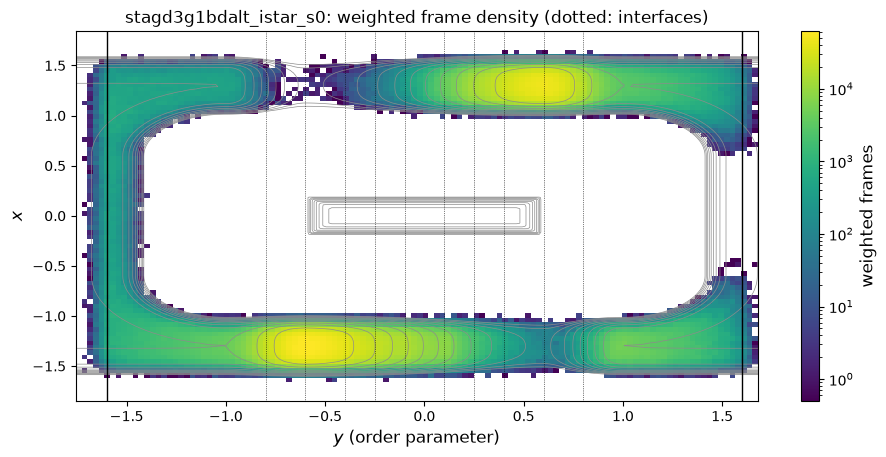

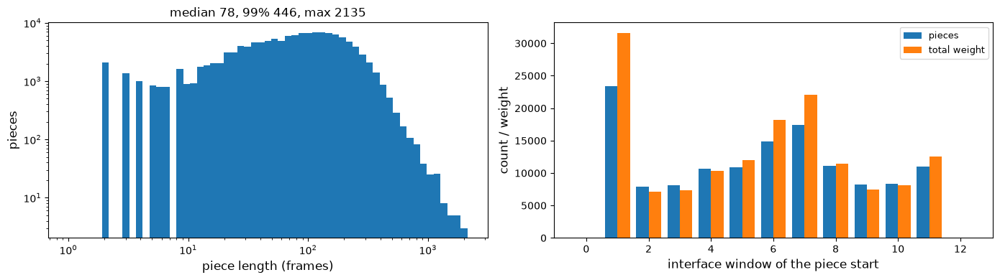

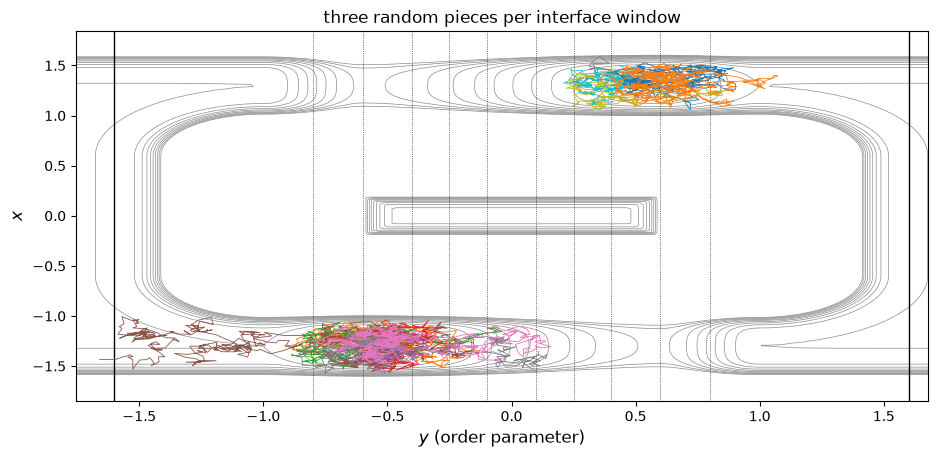

In [7]:
y_lo, y_hi = np.percentile(Y, [0.1, 99.9])
x_lo, x_hi = np.percentile(X, [0.1, 99.9])
pad_y, pad_x = 0.05 * (y_hi - y_lo), 0.1 * (x_hi - x_lo)
Y_RANGE, X_RANGE = (y_lo - pad_y, y_hi + pad_y), (x_lo - pad_x, x_hi + pad_x)
gy, gx = np.linspace(*Y_RANGE, 241), np.linspace(*X_RANGE, 161)
V = toy2d.potential_grid(pot, gy, gx)
V_kT = (V - V.min()) / KT
LEVELS = np.arange(0, 12.5, 1.0)
CONTOURS = (gy, gx, V_kT, LEVELS)
INTFS = run['interfaces']

def draw_potential(ax, intfs=True):
    ax.contour(gy, gx, V_kT.T, levels=LEVELS, colors='0.55', linewidths=0.5)
    if intfs:
        for lam in INTFS:
            ax.axvline(lam, color='k', lw=0.5, ls=':')
        for lam in (LAMBDA_A, LAMBDA_B):
            ax.axvline(lam, color='k', lw=1)
    ax.set(xlim=Y_RANGE, ylim=X_RANGE, xlabel='$y$ (order parameter)', ylabel='$x$')

ey, ex = np.linspace(*Y_RANGE, 121), np.linspace(*X_RANGE, 81)
Hw = np.histogram2d(Y, X, [ey, ex], weights=W)[0]
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.pcolormesh(ey, ex, np.where(Hw > 0, Hw, np.nan).T, norm='log', cmap='viridis')
draw_potential(ax)
fig.colorbar(im, ax=ax, label='weighted frames')
ax.set_title(f'{RUN}: weighted frame density (dotted: interfaces)')
save_fig('data_density')
plt.show()

ends = np.r_[np.flatnonzero(np.diff(data.i_traj) != 0), len(Y) - 1]
starts = np.r_[0, ends[:-1] + 1]
lengths = ends - starts + 1
piece_lam0 = Y[starts]
ens_of_piece = np.digitize(piece_lam0, INTFS)                 # rough ensemble label: interface window of the start
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.hist(lengths, bins=np.logspace(0, np.log10(lengths.max() + 1), 60))
ax1.set(xscale='log', yscale='log', xlabel='piece length (frames)', ylabel='pieces',
        title=f'median {np.median(lengths):.0f}, 99% {np.percentile(lengths, 99):.0f}, max {lengths.max()}')
piece_w = W[starts]
cnt = np.bincount(ens_of_piece, minlength=len(INTFS) + 1)
wsum = np.bincount(ens_of_piece, weights=piece_w, minlength=len(INTFS) + 1)
ax2.bar(np.arange(len(cnt)) - 0.2, cnt, 0.4, label='pieces')
ax2.bar(np.arange(len(cnt)) + 0.2, wsum, 0.4, label='total weight')
ax2.set(xlabel='interface window of the piece start', ylabel='count / weight')
ax2.legend()
fig.tight_layout()
save_fig('data_pieces')
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.8))
draw_potential(ax)
rng = np.random.default_rng(0)
for k in np.unique(ens_of_piece):
    sel = np.flatnonzero(ens_of_piece == k)
    for i in rng.choice(sel, size=min(3, sel.size), replace=False):
        s0, s1 = starts[i], ends[i] + 1
        ax.plot(Y[s0:s1], X[s0:s1], lw=0.6, color=f'C{k % 10}')
ax.set_title('three random pieces per interface window')
save_fig('data_example_pieces')
plt.show()

if V_ORD and not BROWNIAN:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    vg = np.linspace(-5, 5, 200) * np.sqrt(KT / MASS)
    for ax, name in zip(axes, ('vy', 'vx')):
        ax.hist(cols[name][free][::5], bins=100, density=True, weights=W[free][::5], alpha=0.6, label='frames (weighted)')
        ax.plot(vg, np.exp(-MASS * vg ** 2 / (2 * KT)) / np.sqrt(2 * np.pi * KT / MASS), 'k--', label='Maxwell')
        ax.set(xlabel=name)
        ax.legend()
    fig.tight_layout()
    save_fig('data_velocities')
    plt.show()

## 5. References and the Data Test

For Brownian runs: the exact committor on a grid, interpolated to every frame, and the **data test**: the worst |stopped Z_q / standard error| of the exact committor on these data, per lag (it should be ≲ 2–3 at every lag; a failure means the data, not the fit, are off), with the MC weights and with every path once. Caveat: at long lags the low ensembles (q ≈ 0) can fail even for the exact committor, because the rare paths that climb to the plateau before turning are missing from a sample of a few thousand paths (an undersampled tail, not a bias); judge the weights mainly at short and intermediate lags. For both dynamics: the shooting reference at random frames (Langevin needs recorded velocities; for Brownian runs it also checks the grid solution).

-1.6 1.6
data test, exact committor, rejections weights: worst |z| at lags (1, 4, 16, 64, 256, 1024, 2048, 4096, 8192, 16284, 32768) : 1.6 1.6 1.2 2.2 2.4 2.5 2.5 2.5 2.5 2.5 2.5
data test, exact committor, without weights: worst |z| at lags (1, 4, 16, 64, 256, 1024, 2048, 4096, 8192, 16284, 32768) : 7.6 6.4 3.0 1.8 1.9 2.0 2.0 2.0 2.0 2.0 2.0


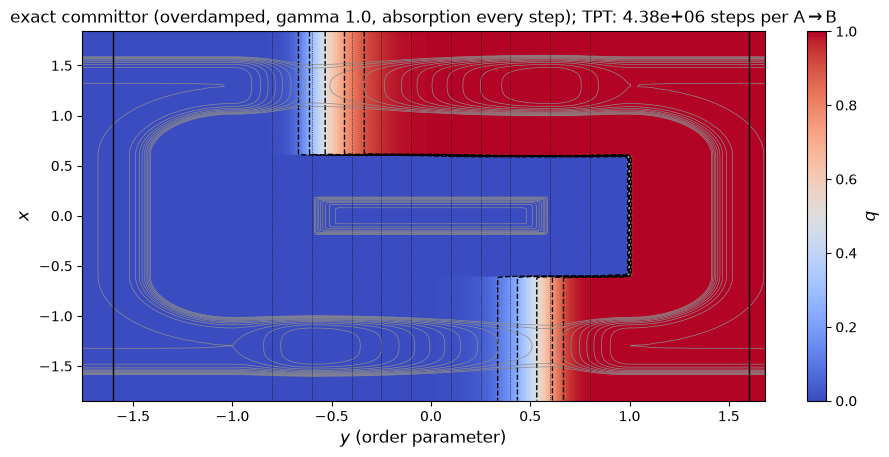

KeyboardInterrupt: 

In [8]:
LAGS = (1, 4, 16, 64, 256, 1024, 2048, 4096, 8192, 16284, 32768)
ref = q_exact = None
print(LAMBDA_A, LAMBDA_B)
if BROWNIAN:
    ref = toy2d.exact_committor_brownian(pot, KT, GAMMA, DT, LAMBDA_A, LAMBDA_B, stride=1, mass=MASS,
                                         y_range=Y_RANGE, x_range=X_RANGE)
    q_exact = toy2d.interp_grid(ref, Y, X)
    q_exact[A], q_exact[B] = 0.0, 1.0
    z_exact = {w: toy2d.z_per_lag(q_exact, b, data.i_traj, weights_for(w), LAGS, data.group_traj) for w in FIT_WEIGHTED}
    for w, z in z_exact.items():
        print(f'data test, exact committor, {label_of(w)}: worst |z| at lags', LAGS, ':', ' '.join(f'{v:.1f}' for v in z))
    fig, ax = plt.subplots(figsize=(11, 4.8))
    im = ax.pcolormesh(ref['y'], ref['x'], ref['q'].T, cmap='coolwarm', vmin=0, vmax=1)
    ax.contour(ref['y'], ref['x'], ref['q'].T, levels=[0.1, 0.25, 0.5, 0.75, 0.9], colors='k', linestyles='--', linewidths=1)
    draw_potential(ax)
    fig.colorbar(im, ax=ax, label='$q$')
    ax.set_title(f'exact committor (overdamped, gamma {GAMMA}, absorption every step); TPT: {ref["steps_per_ab"]:.3g} steps per A$\\to$B')
    save_fig('exact_committor')
    plt.show()

shoot_idx = np.array([], int)
can_shoot = N_SHOOT_POINTS > 0 and (BROWNIAN or V_ORD) and hasattr(pot, 'potential_and_force_xy')
if can_shoot:
    rng = np.random.default_rng(1)
    shoot_idx = np.sort(rng.choice(np.flatnonzero(free), size=min(N_SHOOT_POINTS, free.sum()), replace=False))
    vy0 = cols['vy'][shoot_idx] if V_ORD else None
    vx0 = cols['vx'][shoot_idx] if V_ORD else None
    t0 = time.time()
    q_shoot, se_shoot = toy2d.shoot(pot, Y[shoot_idx], X[shoot_idx], vy0, vx0, N_SHOTS, DT, KT, GAMMA,
                                    LAMBDA_A, LAMBDA_B, MASS, BROWNIAN, xp=cp, progress=True)
    print(f'shooting: {len(shoot_idx)} frames x {N_SHOTS} trajectories in {time.time() - t0:.0f} s, '
          f'mean standard error {np.nanmean(se_shoot):.3f}')
    if q_exact is not None:
        d = q_exact[shoot_idx] - q_shoot
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.errorbar(q_shoot, q_exact[shoot_idx], xerr=se_shoot, fmt='.', ms=3, alpha=0.6)
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set(xlabel='shooting', ylabel='exact (grid)', title=f'grid vs shooting: RMS {np.sqrt(np.mean(d ** 2)):.3f}')
        save_fig('exact_vs_shooting')
        plt.show()
else:
    print('no shooting reference (needs a vectorized potential, and recorded velocities for Langevin runs)')

md_ref = None
if MD_COMMITTOR_NPZ is not None:
    md_ref = np.load(MD_COMMITTOR_NPZ)
    print('MD reference', MD_COMMITTOR_NPZ, '| settings', str(md_ref['settings']))

## 6. Fit the Committor

One fit per entry of `FIT_WEIGHTED` (with the path weights, and with every path weighted 1), on the same frames. `CommittorNE` with `group_traj` (forward and mirrored piece of a path as one unit), A/B ends as traps (longer than any piece plus the longest Z_q lag, so no window is dropped), turn ends stopped with `set_stopped_traj_end` (`STOPPED_ENDS`; the `feps` Z_q is then the stopped Z_q), and the update of `FIT_LAG` (`toy2d.lag_update`). The cell builds the committor, runs `fit_transform` for the warm-up and then in chunks, and `seed_runs.save_and_show` shows and saves, after the warm-up and every `CHUNK` iterations: `metrics`, `tis` (stopped Z_q per lag, short-lag Z_q, stopped obs vs pred), `feps`, `obs_pred`, `obs_pred_log` (the last three are the original, unstopped versions, biased for path pieces), and the fitted q against the CVs (with the exact committor for Brownian runs). Convergence: `zqs_z` ≲ 2 (judge a lag-Δ fit at lags ≥ Δ).

In [9]:
X_cv = cp.asarray(np.column_stack([cols[c] for c in CVS]))
e_y = np.linspace(LAMBDA_A, LAMBDA_B, 71)
e_x = np.linspace(*np.percentile(X[free], [0.5, 99.5]), 41)
planes = [seed_runs.plane(Y, e_y, '$y$', X, e_x, '$x$', CONTOURS)]
vel = [c for c in CVS if c in ('vy', 'vx', 'dy', 'dx')]
for c in vel:
    lim = np.percentile(np.abs(cols[c][free]), 99)
    planes.append(seed_runs.plane(Y, e_y, '$y$', cols[c], np.linspace(-lim, lim, 41), c))

# piece ends: in A or B (trap), or at a turn (stopped: windows past the end use q there)
piece_end = np.r_[np.flatnonzero(np.diff(data.i_traj)), len(Y) - 1]
stop_end = np.zeros(len(Y), bool)
stop_end[piece_end] = ~b[piece_end]
TRAP_LEN = max(2 ** 16, int(np.bincount(data.i_traj - data.i_traj.min()).max()) + 2 ** 15 + 1)   # Z_q lags go up to 2^15
print(f'{len(piece_end)} pieces: {stop_end.sum()} end at a turn, {len(piece_end) - stop_end.sum()} in A or B; A/B trap {TRAP_LEN}')

PRINT_STEP = min(500, CHUNK, WARMUP_ITER or CHUNK)
METRICS = ['delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x']
mid_y = (e_y[1:] + e_y[:-1]) / 2
prof_ref = None if q_exact is None else seed_runs.BinnedMean((Y,), (e_y,), free, MIN_COUNT)(q_exact)
extras = {'q_map': seed_runs.committor_map(planes[:1], mask=free, q_ref=q_exact, min_count=MIN_COUNT),
          'q_profile': seed_runs.committor_profile(Y, e_y, '$y$', mask=free,
                                                   ref=None if prof_ref is None else (mid_y, prof_ref))}
if len(planes) > 1:
    extras['q_velocity_planes'] = seed_runs.committor_map(planes[1:], mask=free, min_count=MIN_COUNT)

def report(q):
    r = cp.asnumpy(q.r_traj)
    h = q.metrics_history.get('max_z_zq_stopped', [np.nan])
    out = f'| zqs_z {h[-1]:.2f}'
    if q_exact is not None:
        bm = seed_runs.BinnedMean(planes[0]['c'], planes[0]['edges'], free, MIN_COUNT)
        Qf, Qe = bm(r), bm(q_exact)
        t = (Qe > 0.05) & (Qe < 0.95)
        out += f' | RMS(fit - exact) per bin {np.sqrt(np.nanmean((Qf - Qe)[t] ** 2)):.4f}'
    if shoot_idx.size:
        out += f' | vs shooting {np.sqrt(np.nanmean((r[shoot_idx] - q_shoot) ** 2)):.4f}'
    return out

PLOTS = ('metrics', 'tis', 'feps', 'obs_pred', 'obs_pred_log')     # saved and shown after every stage

def comp_y():
    """The CV of an iteration: one of the fit CVs, drawn at random."""
    return X_cv[:, np.random.randint(X_cv.shape[1])]

def show_stage(q, folder, n_done, stage):
    """Save and show the plots after a stage (FOLDER/it<N>_<plot>.png), and print the progress."""
    seed_runs.save_and_show(q, folder, f'it{n_done}', PLOTS, dict(metrics=METRICS), extras)
    print(f'{n_done} iterations ({stage}) {report(q)}', flush=True)

131863 pieces: 117734 end at a turn, 14129 in A or B; A/B trap 65536


131863 pieces: 117734 end at a turn, 14129 in A or B; A/B trap 65536
===== fit, rejections weights, seed 0: rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped =====
#=500, dr2=114.571, zqs_z=4.37378, sdzqs=2.84033, |dx|=0.492505, time=31.4783
#=1000, dr2=114.426, zqs_z=4.37587, sdzqs=2.71014, |dx|=0.000266839, time=73.9736
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it1000 ---


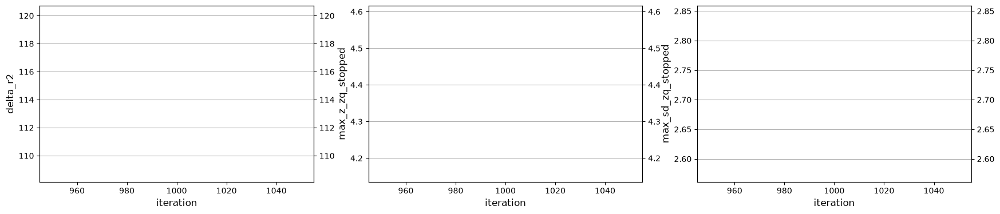

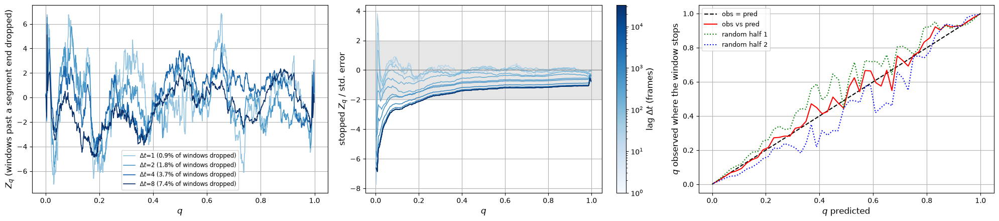

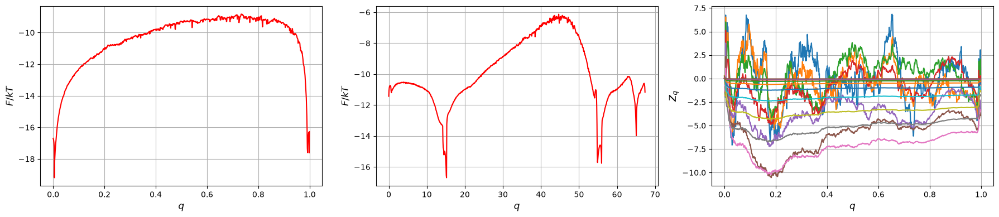

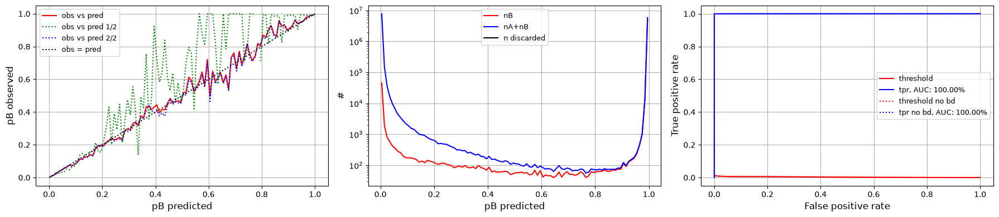

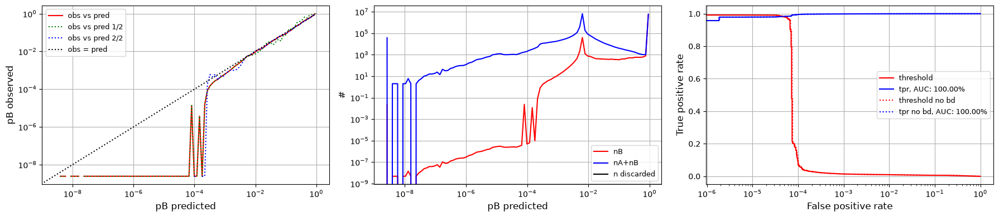

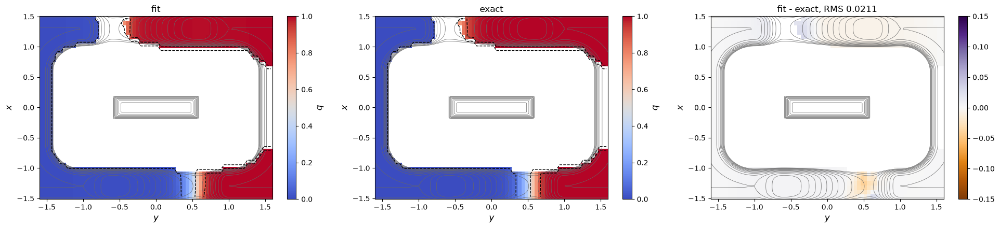

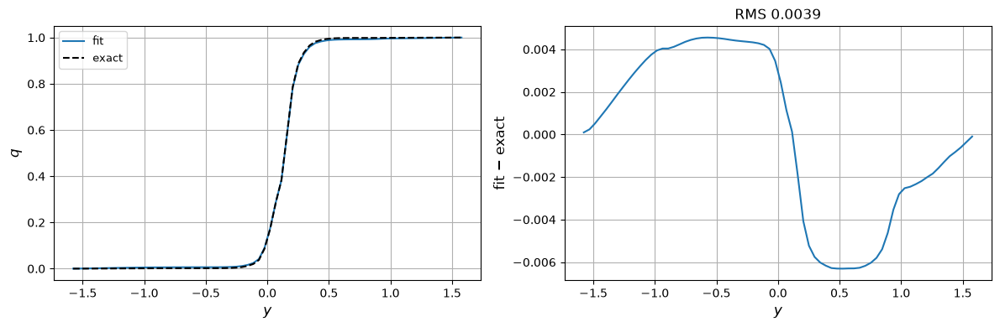

1000 iterations (warm-up, envelope 1000000) | zqs_z 4.38 | RMS(fit - exact) per bin 0.0211
#=1500, dr2=114.314, zqs_z=1.68352, sdzqs=2.2978, |dx|=0.00506522, time=29.3533
#=2000, dr2=114.167, zqs_z=1.65272, sdzqs=2.33705, |dx|=0.000109619, time=71.8764
#=2500, dr2=114.135, zqs_z=1.70499, sdzqs=2.35304, |dx|=8.72044e-05, time=113.754
#=3000, dr2=114.113, zqs_z=1.75872, sdzqs=2.36283, |dx|=4.65103e-05, time=156.275
#=3500, dr2=114.232, zqs_z=1.48566, sdzqs=1.98123, |dx|=0.00104842, time=190.858
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it3500 ---


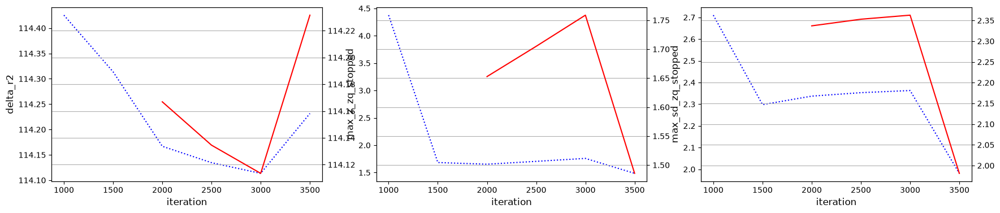

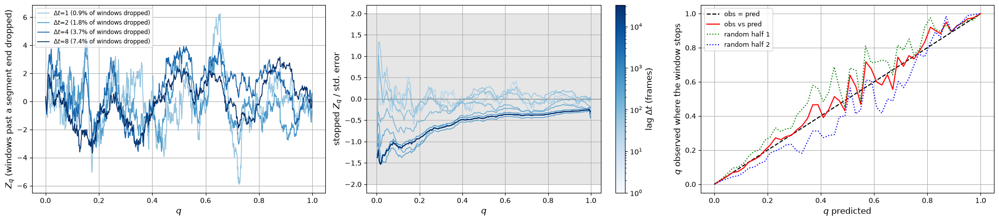

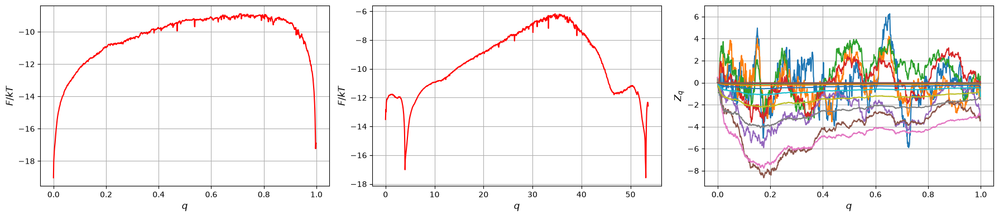

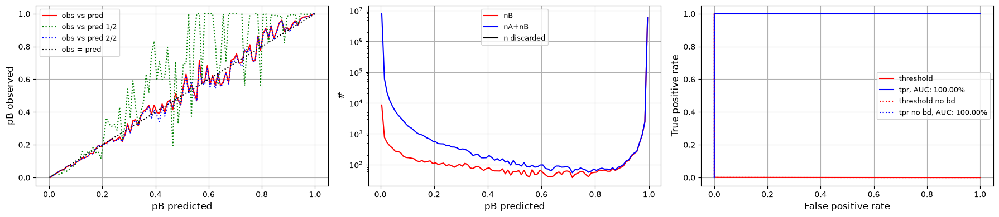

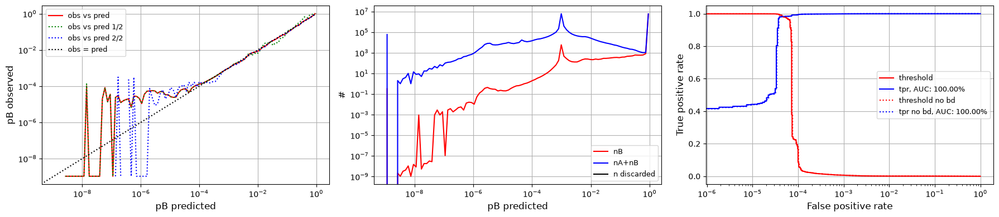

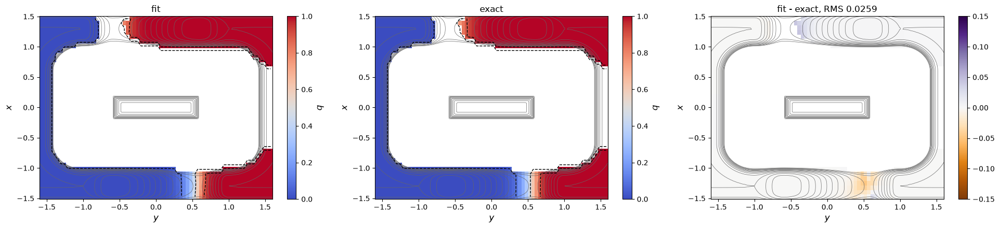

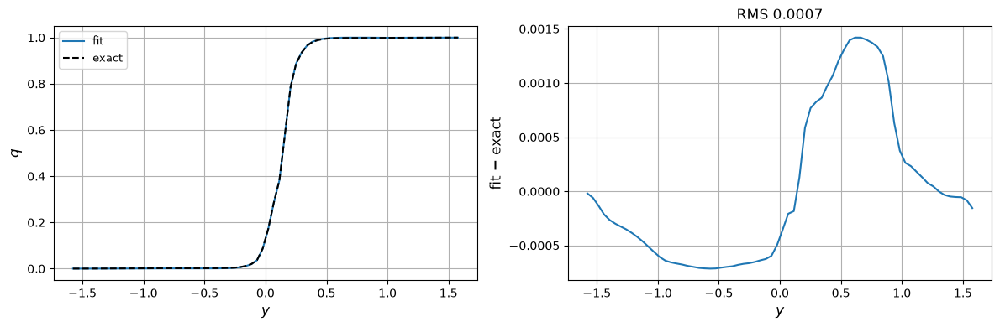

3500 iterations (main, envelope 0.01) | zqs_z 1.49 | RMS(fit - exact) per bin 0.0259
#=4000, dr2=114.277, zqs_z=1.57279, sdzqs=1.98524, |dx|=0.000612868, time=40.3538
#=4500, dr2=114.165, zqs_z=1.57495, sdzqs=2.02926, |dx|=0.000285006, time=82.8524
#=5000, dr2=114.206, zqs_z=1.56471, sdzqs=2.06334, |dx|=0.000167353, time=125.372
#=5500, dr2=114.115, zqs_z=1.58056, sdzqs=2.06841, |dx|=0.000187432, time=167.183
#=6000, dr2=114.193, zqs_z=1.55035, sdzqs=2.07553, |dx|=0.00042703, time=191.835
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it6000 ---


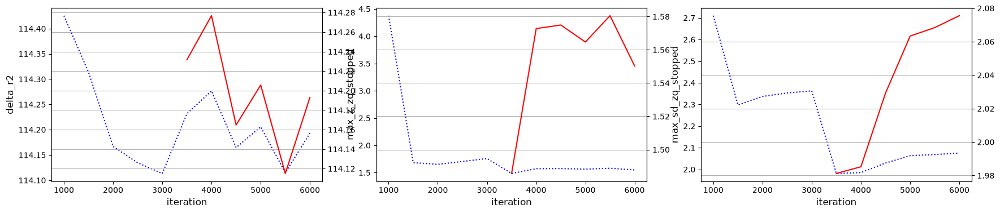

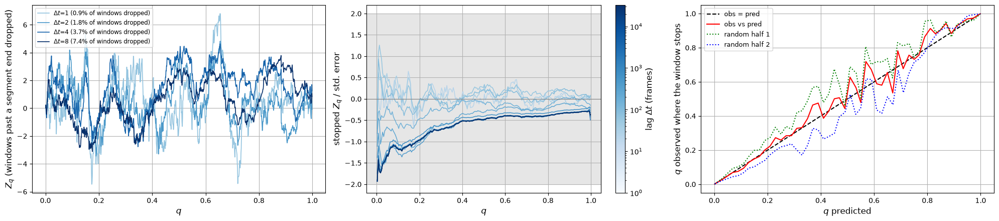

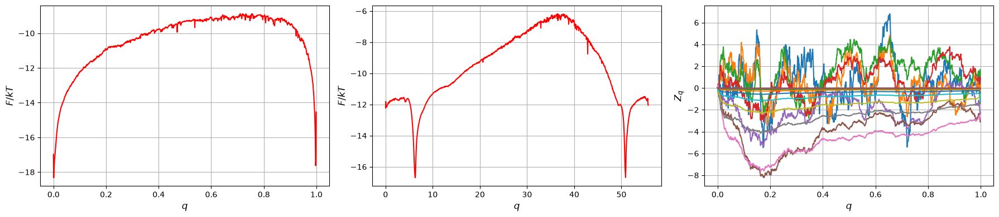

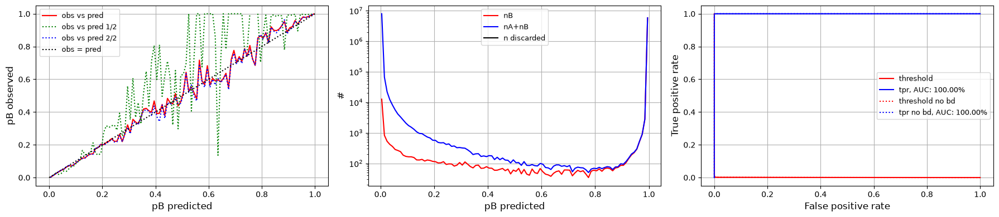

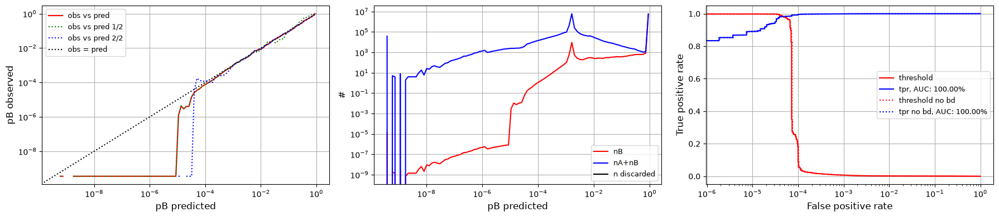

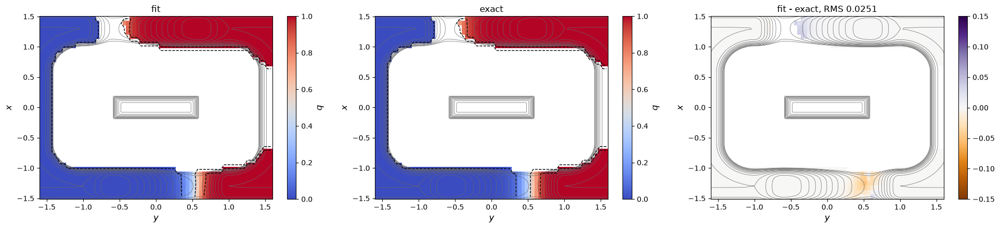

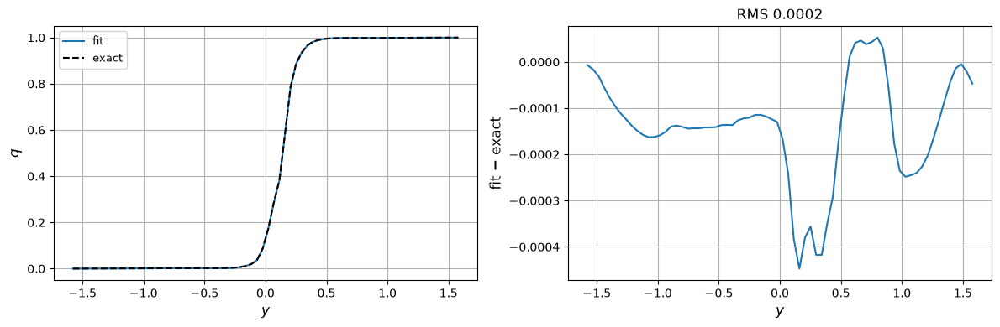

6000 iterations (main, envelope 0.01) | zqs_z 1.55 | RMS(fit - exact) per bin 0.0251
#=6500, dr2=114.149, zqs_z=1.53278, sdzqs=2.07947, |dx|=0.000265148, time=42.2728
#=7000, dr2=114.158, zqs_z=1.5441, sdzqs=2.10331, |dx|=0.000112142, time=83.7825
#=7500, dr2=114.032, zqs_z=1.54188, sdzqs=2.11601, |dx|=0.000284209, time=126.394
#=8000, dr2=114.05, zqs_z=1.56208, sdzqs=2.10514, |dx|=9.25297e-05, time=159.97
#=8500, dr2=112.447, zqs_z=3.31029, sdzqs=2.15927, |dx|=0.00361736, time=191.416
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it8500 ---


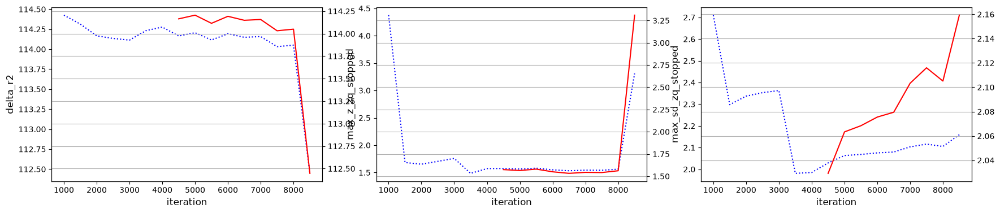

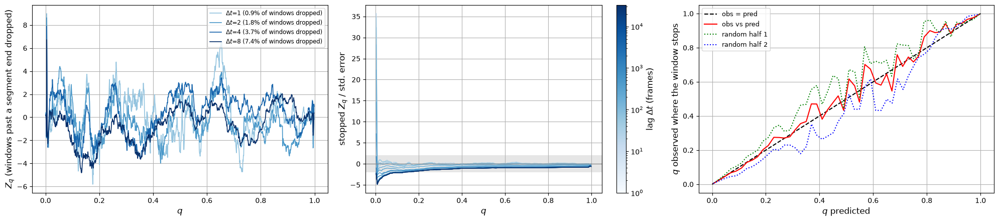

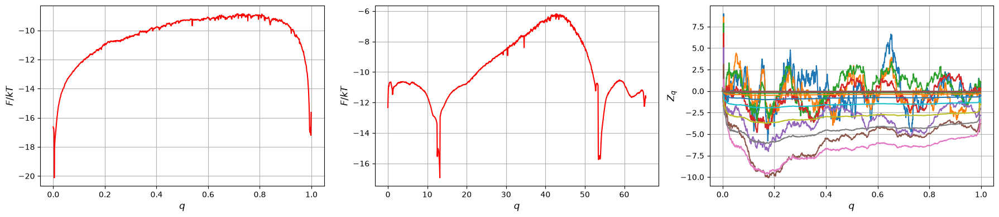

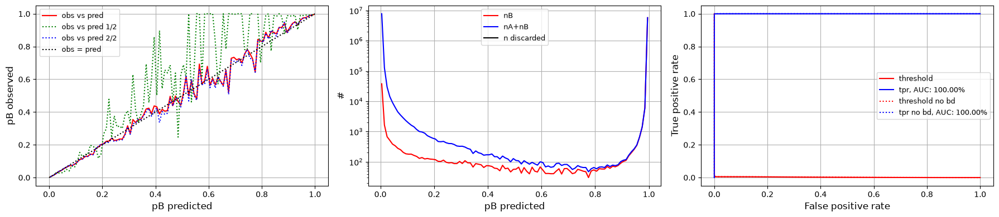

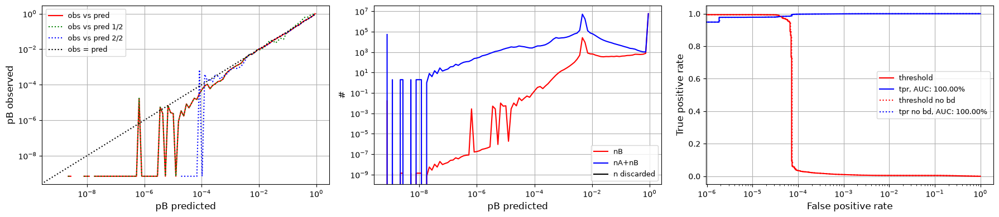

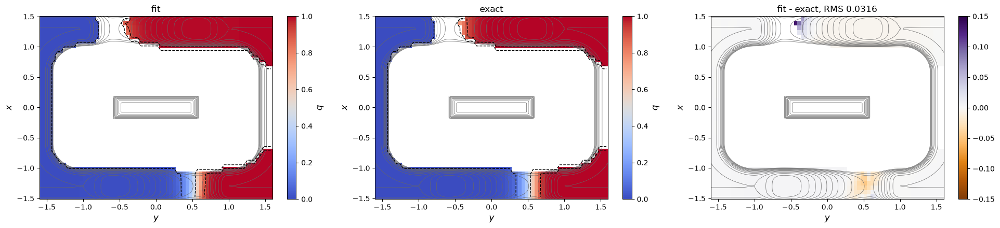

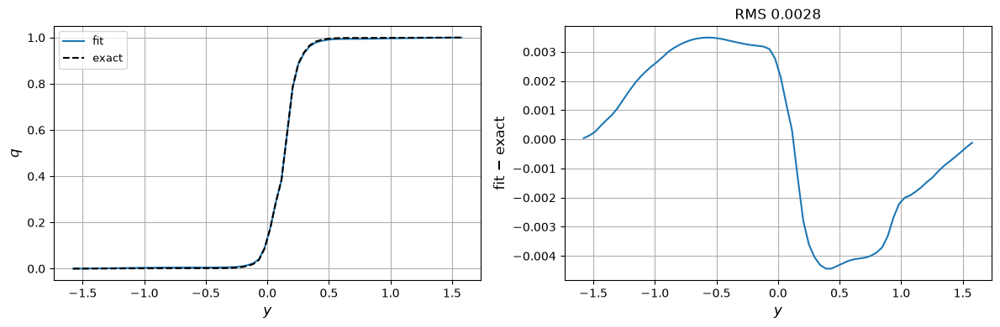

8500 iterations (main, envelope 0.01) | zqs_z 3.31 | RMS(fit - exact) per bin 0.0316
#=9000, dr2=113.614, zqs_z=1.58278, sdzqs=2.09327, |dx|=0.00353149, time=42.3264
#=9500, dr2=112.535, zqs_z=3.37581, sdzqs=2.02647, |dx|=0.00201023, time=84.7269
#=10000, dr2=113.13, zqs_z=1.75024, sdzqs=1.9399, |dx|=0.00214617, time=125.445
#=10500, dr2=112.887, zqs_z=1.78186, sdzqs=1.87695, |dx|=0.000626447, time=149.686
#=11000, dr2=112.968, zqs_z=1.6907, sdzqs=1.90479, |dx|=0.000419642, time=192.381
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it11000 ---


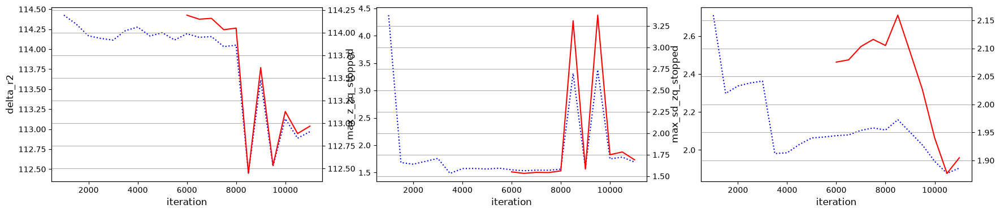

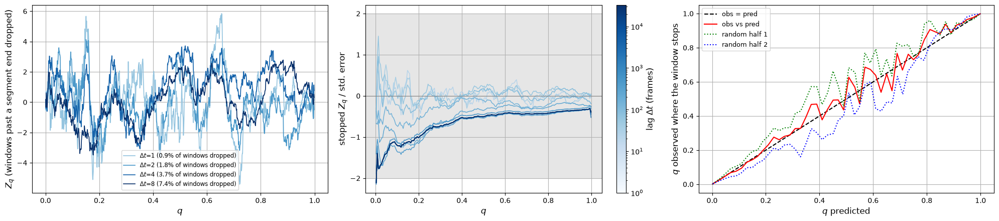

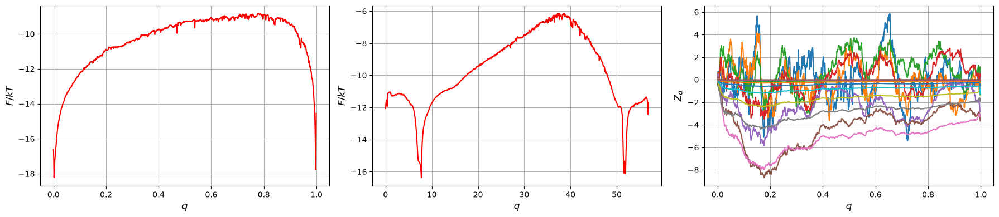

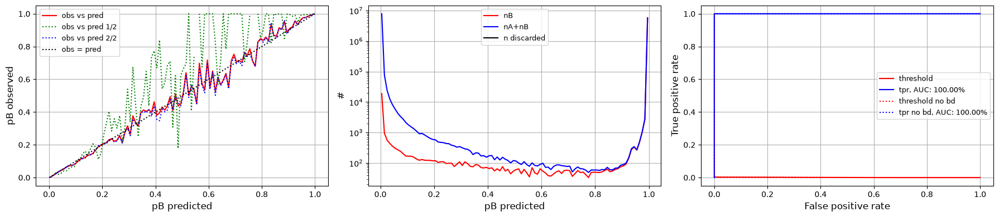

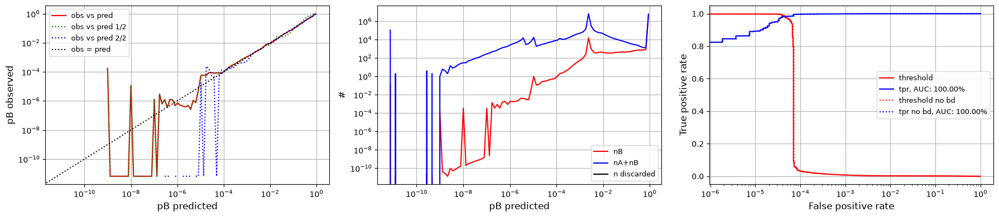

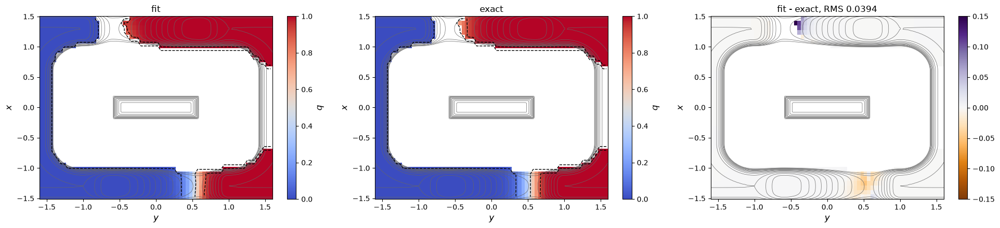

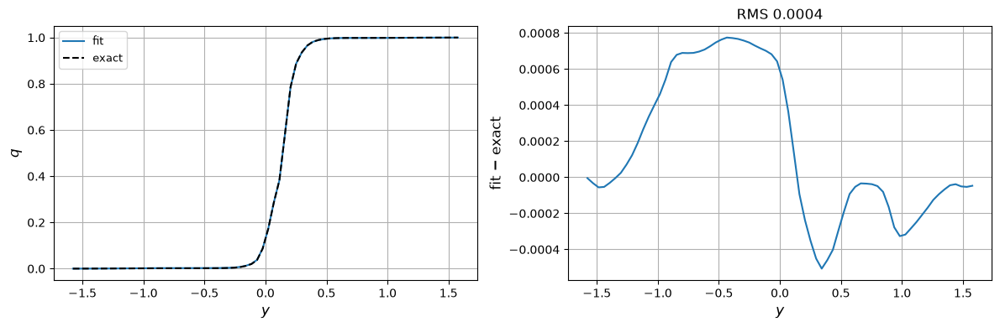

11000 iterations (main, envelope 0.01) | zqs_z 1.69 | RMS(fit - exact) per bin 0.0394
===== fit, without weights, seed 0: rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped =====
#=500, dr2=108.006, zqs_z=3.89059, sdzqs=1.45584, |dx|=0.494011, time=42.7682
#=1000, dr2=107.994, zqs_z=3.90594, sdzqs=1.45704, |dx|=5.77968e-05, time=85.4288
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it1000 ---


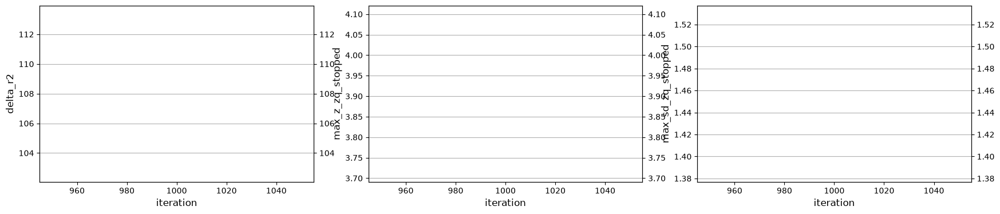

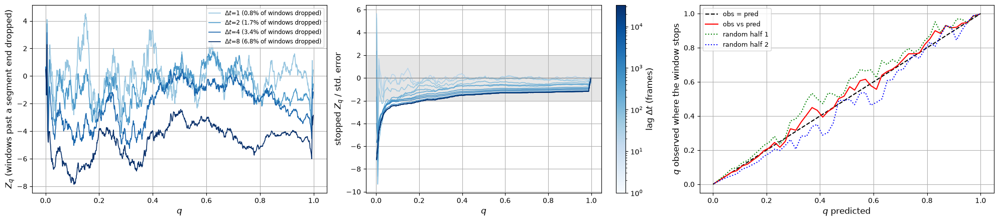

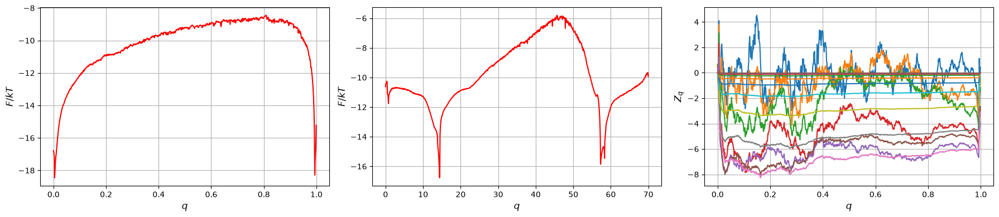

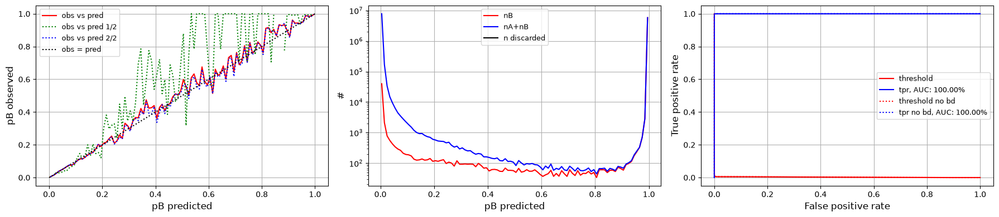

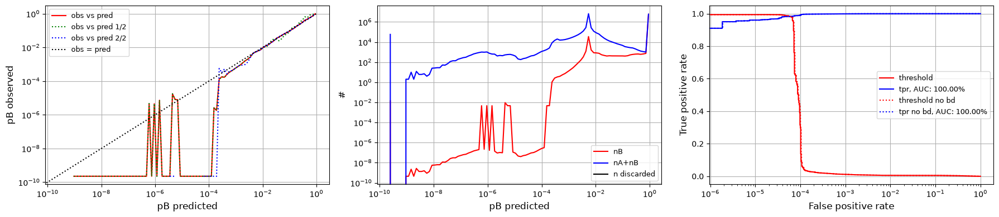

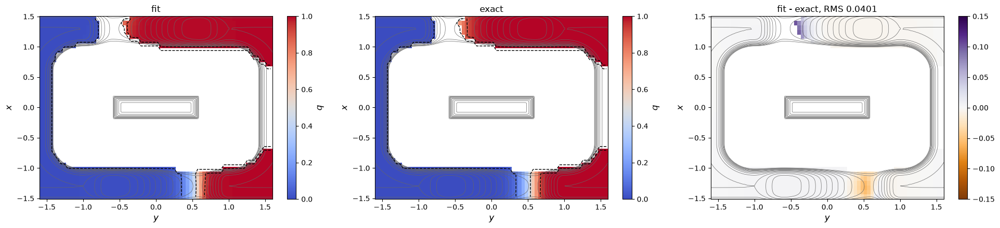

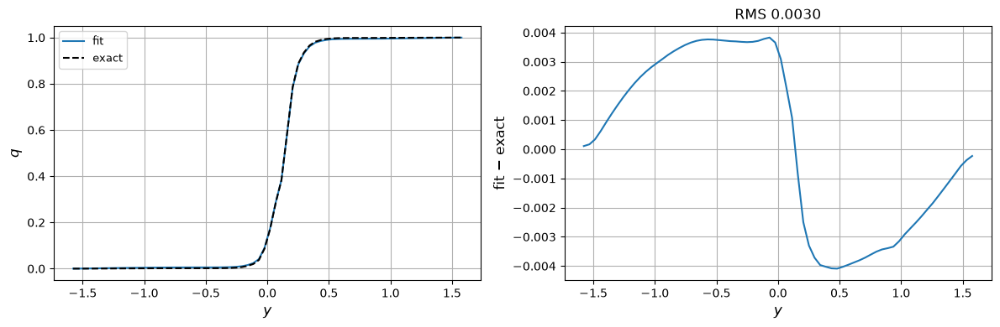

1000 iterations (warm-up, envelope 1000000) | zqs_z 3.91 | RMS(fit - exact) per bin 0.0401
#=1500, dr2=107.869, zqs_z=3.14408, sdzqs=1.41189, |dx|=0.00316971, time=27.2209
#=2000, dr2=107.828, zqs_z=3.11624, sdzqs=1.36432, |dx|=7.33394e-05, time=69.8252
#=2500, dr2=107.819, zqs_z=3.11187, sdzqs=1.35802, |dx|=2.33218e-05, time=111.965
#=3000, dr2=107.784, zqs_z=3.13217, sdzqs=1.35121, |dx|=9.54045e-05, time=154.014
#=3500, dr2=108.133, zqs_z=3.03506, sdzqs=1.37615, |dx|=0.000425181, time=190.957
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it3500 ---


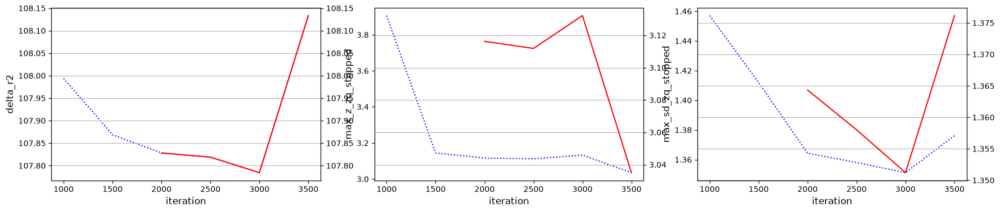

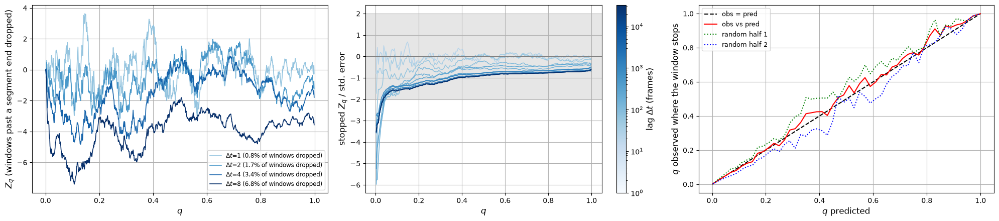

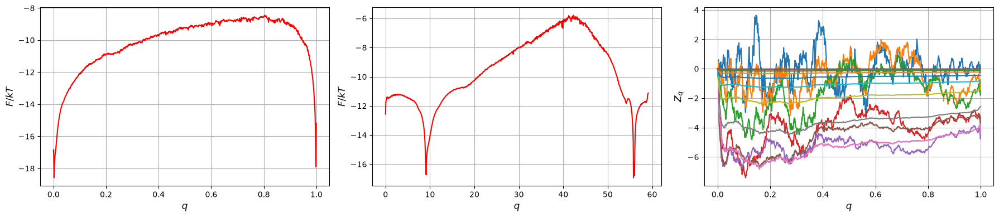

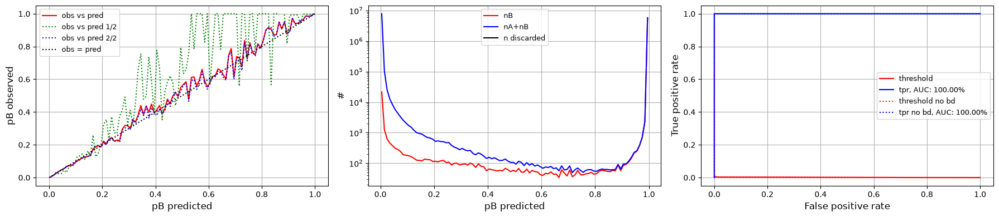

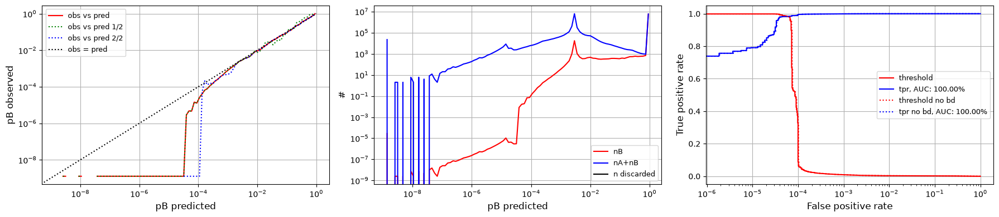

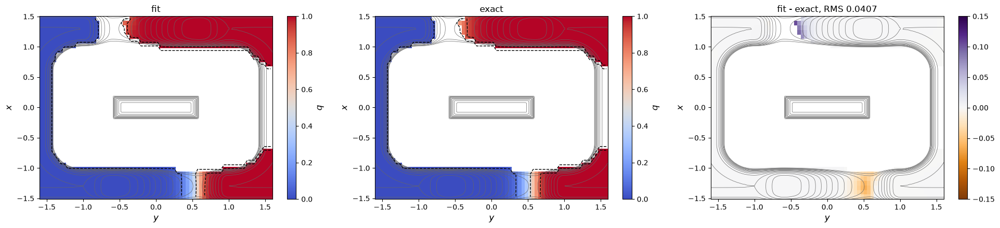

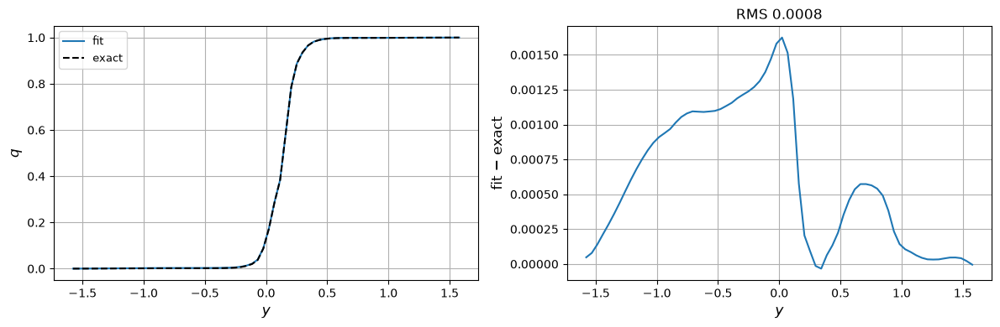

3500 iterations (main, envelope 0.01) | zqs_z 3.04 | RMS(fit - exact) per bin 0.0407
#=4000, dr2=108.088, zqs_z=3.09797, sdzqs=1.36622, |dx|=0.000157093, time=39.631
#=4500, dr2=108.094, zqs_z=3.11412, sdzqs=1.35823, |dx|=3.42352e-05, time=82.1695
#=5000, dr2=108.104, zqs_z=3.10022, sdzqs=1.35778, |dx|=0.000145534, time=124.853
#=5500, dr2=108.103, zqs_z=3.10795, sdzqs=1.3558, |dx|=1.75635e-05, time=166.996
#=6000, dr2=108.089, zqs_z=3.09932, sdzqs=1.35379, |dx|=0.000149813, time=192.167
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it6000 ---


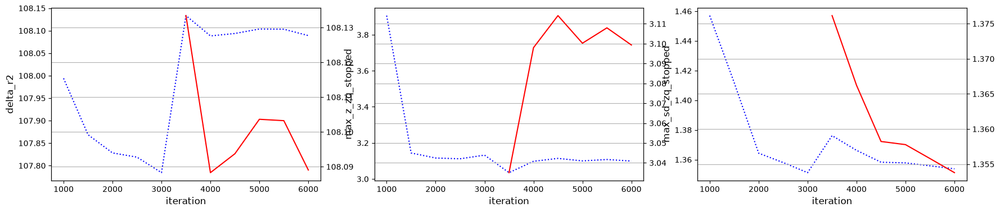

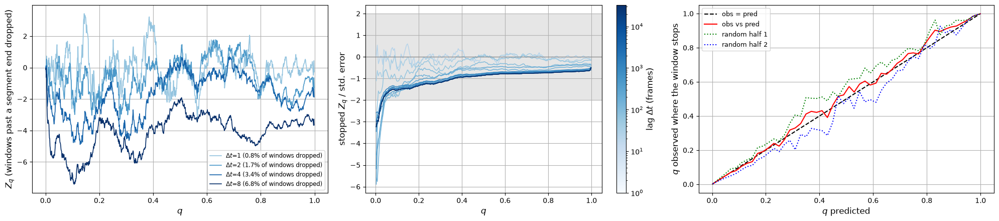

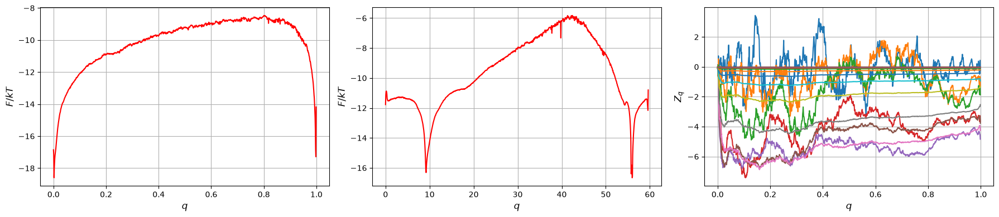

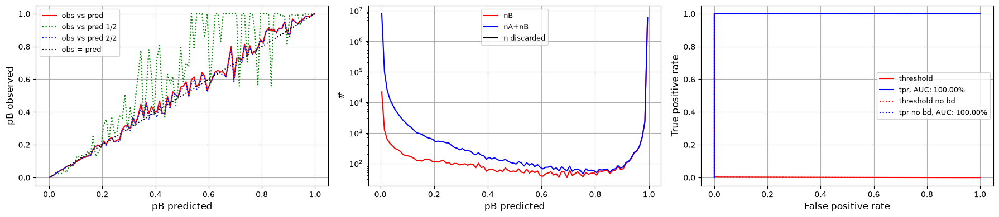

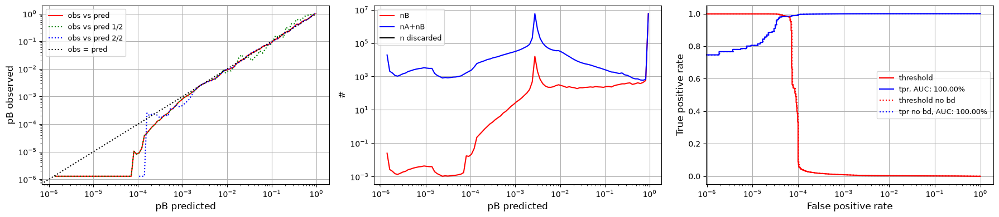

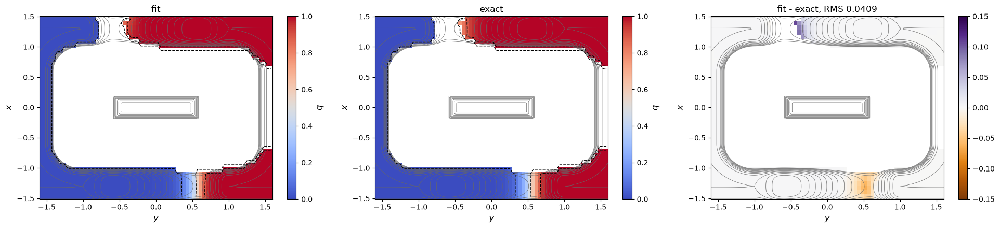

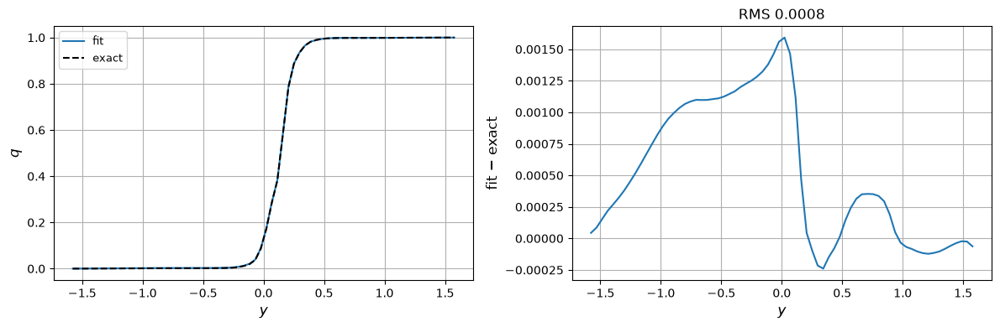

6000 iterations (main, envelope 0.01) | zqs_z 3.10 | RMS(fit - exact) per bin 0.0409
#=6500, dr2=108.097, zqs_z=3.08468, sdzqs=1.35878, |dx|=0.000170158, time=42.4239
#=7000, dr2=108.09, zqs_z=3.08325, sdzqs=1.35347, |dx|=0.00011498, time=84.1738
#=7500, dr2=108.107, zqs_z=3.07911, sdzqs=1.35182, |dx|=4.18716e-05, time=126.88
#=8000, dr2=108.095, zqs_z=3.07356, sdzqs=1.3483, |dx|=4.81837e-05, time=160.791
#=8500, dr2=108.317, zqs_z=3.11975, sdzqs=1.4188, |dx|=0.000348406, time=191.795
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it8500 ---


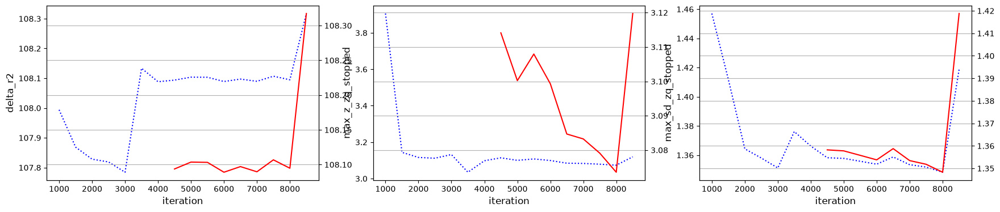

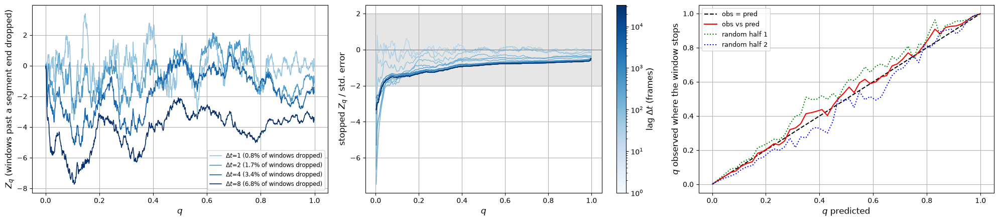

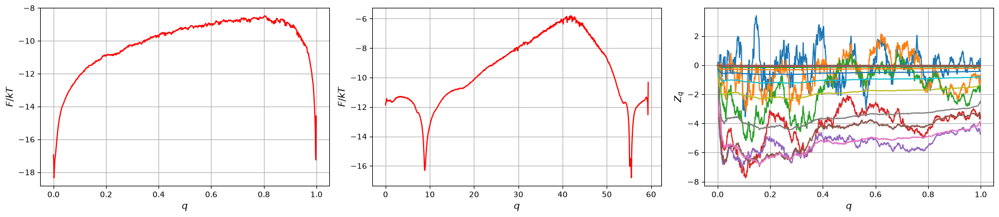

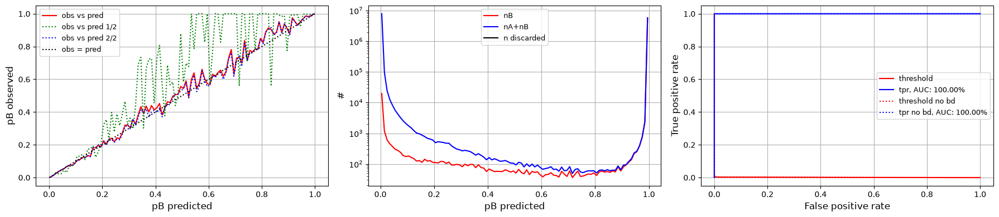

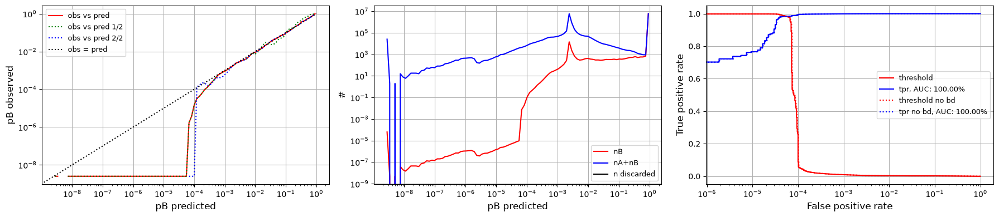

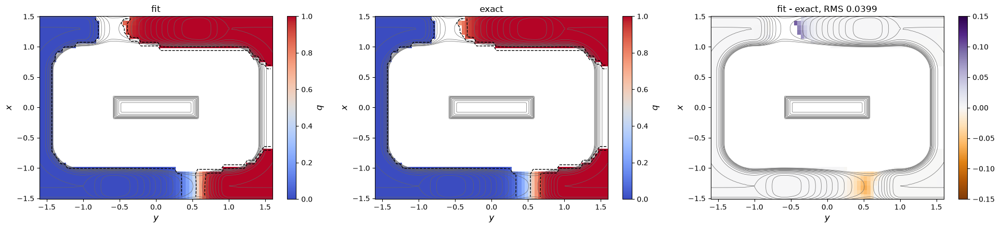

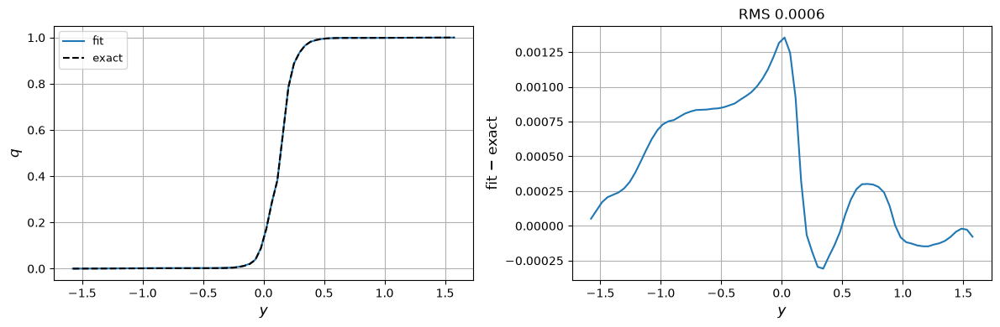

8500 iterations (main, envelope 0.01) | zqs_z 3.12 | RMS(fit - exact) per bin 0.0399
#=9000, dr2=108.264, zqs_z=3.15464, sdzqs=1.41237, |dx|=0.000198651, time=42.355
#=9500, dr2=108.259, zqs_z=3.14442, sdzqs=1.39951, |dx|=0.00015129, time=84.8047
#=10000, dr2=108.225, zqs_z=3.11668, sdzqs=1.39454, |dx|=0.000157297, time=125.593
#=10500, dr2=108.226, zqs_z=3.15671, sdzqs=1.3909, |dx|=2.73007e-05, time=149.864
#=11000, dr2=108.209, zqs_z=3.11292, sdzqs=1.38488, |dx|=0.000194935, time=192.488
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped/seed0/it11000 ---


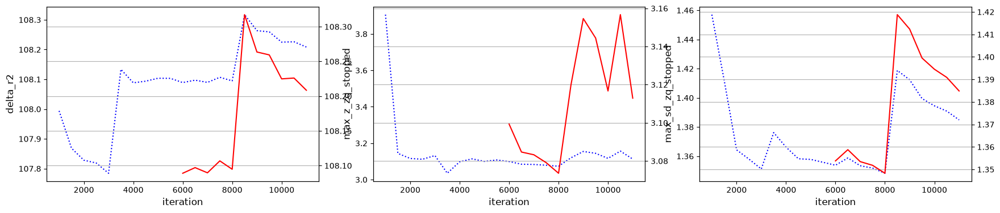

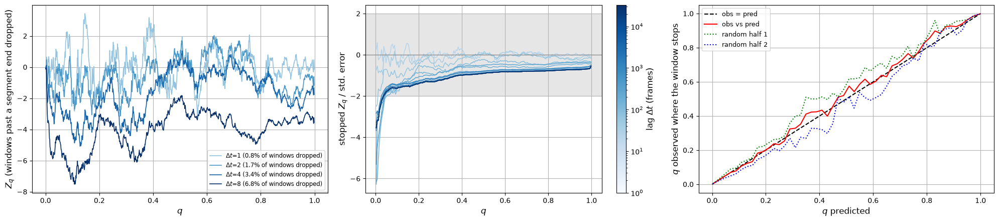

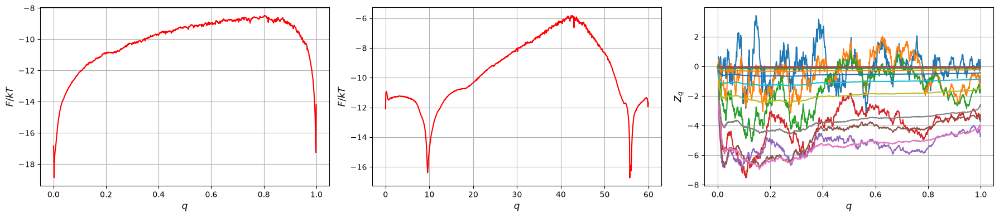

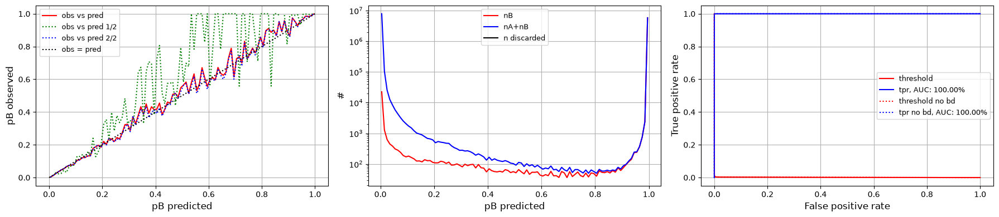

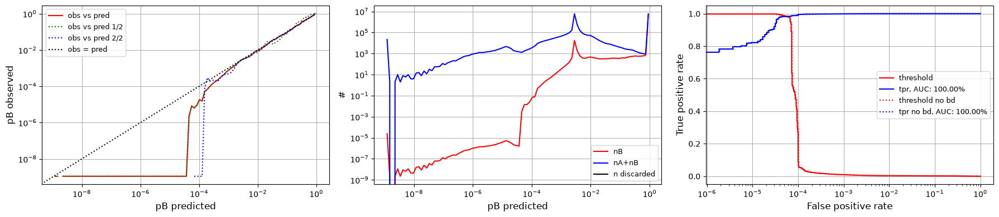

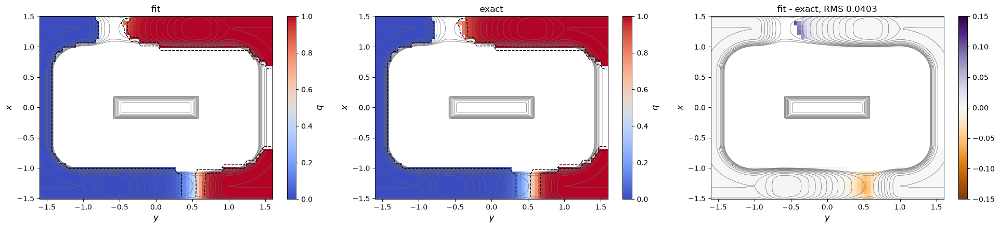

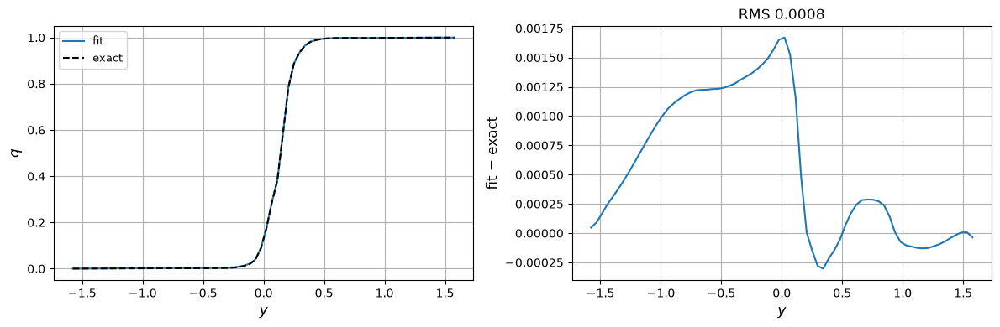

11000 iterations (main, envelope 0.01) | zqs_z 3.11 | RMS(fit - exact) per bin 0.0403


{'lazy_basis': True}

In [13]:
fits = {}                                        # FIT_WEIGHTED entry -> r, tag, weights, results per seed
for weighted in FIT_WEIGHTED:
    W_fit = weights_for(weighted)                # 'none': every path once
    fit_tag = tag_for(weighted)
    fit_kw = dict(ny=NY, print_step=PRINT_STEP, save_min_metric='max_z_zq_stopped',
                  metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'),
                  **toy2d.lag_update(optimalrcs, data.i_traj, b, W_fit, FIT_LAG))   # the update of FIT_LAG
    results = {}
    for seed in FIT_SEEDS:
        print(f'===== fit, {label_of(weighted)}, seed {seed}: {fit_tag} =====')
        np.random.seed(seed)                     # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{FIG_DIR}/{fit_tag}/seed{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=A,                         # state A: q = 0
            boundary1=B,                         # state B: q = 1
            i_traj=data.i_traj,                  # piece of every frame
            t_traj=data.t_traj,                  # MD step of every frame
            path_weights=W_fit,                  # MC weight of the frame's path
            group_traj=data.group_traj,          # path of every frame: its forward and mirrored piece are one unit
        )
        q.set_fixed_traj_length_trap(b, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)     # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=FIT_GAMMA, max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}')

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=FIT_GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}')

        r = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
        results[seed] = dict(r=r, report=report(q))
        del q                                    # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[weighted] = dict(r=results[FIT_SEEDS[-1]]['r'], tag=fit_tag, W=W_fit, results=results)

# the first fit is the main one (used by section 9)
r, fit_tag, results = fits[FIT_WEIGHTED[0]]['r'], fits[FIT_WEIGHTED[0]]['tag'], fits[FIT_WEIGHTED[0]]['results']
q = types.SimpleNamespace(r_traj=cp.asarray(r))
toy2d.lag_update(optimalrcs, data.i_traj, b, weights_for(FIT_WEIGHTED[0]), FIT_LAG)

## 7. Results

For every fit of `FIT_WEIGHTED` (the stopped z of the exact committor is shown with the same weighting):

- The worst stopped z per lag of the fit (and of the exact committor on the same data).
- q against the order parameter: every frame (sample) and the weighted mean per bin, with the exact committor.
- Maps: fit, exact and fit − exact on (y, x); for velocity CVs the fit on (y, v).
- Isocommittor lines of the fit (and the exact committor) on the potential.
- Fit against the shooting reference, and against the MD committor of `toy2d_md.ipynb` if given.
- Seeds: the fits of all `FIT_SEEDS` against each other (if more than one).

===== fit rejections weights: rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped =====


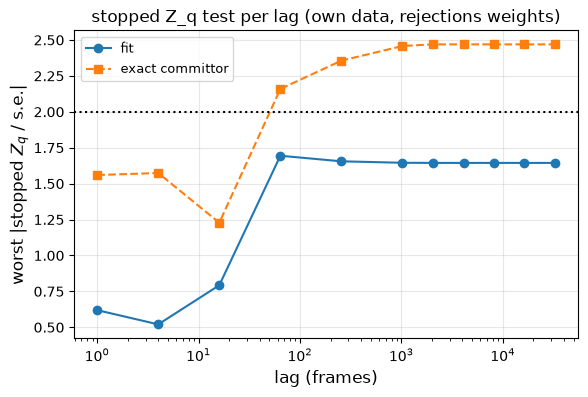

worst |z| per lag (1, 4, 16, 64, 256, 1024, 2048, 4096, 8192, 16284, 32768) : 0.6 0.5 0.8 1.7 1.7 1.6 1.6 1.6 1.6 1.6 1.6


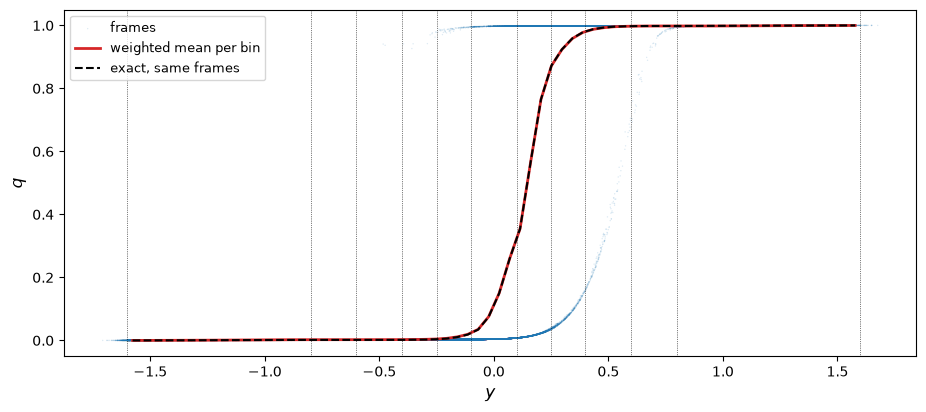

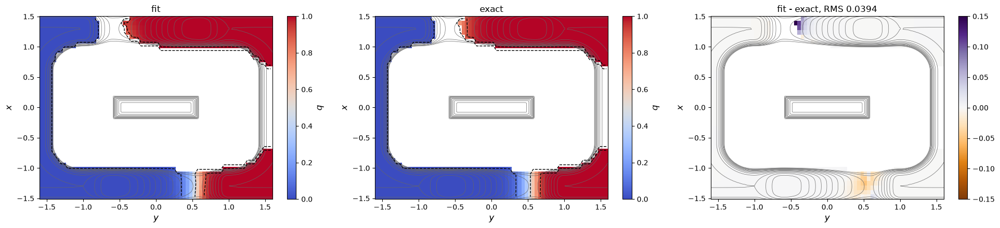

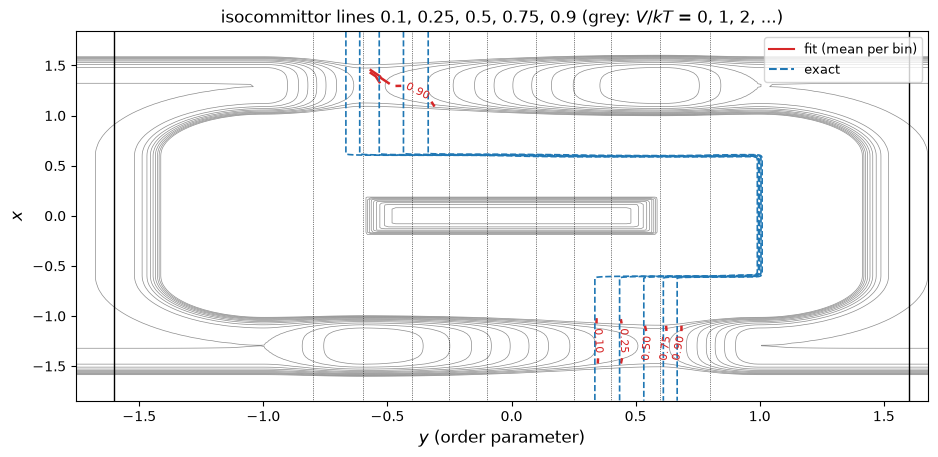

===== fit without weights: rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped =====


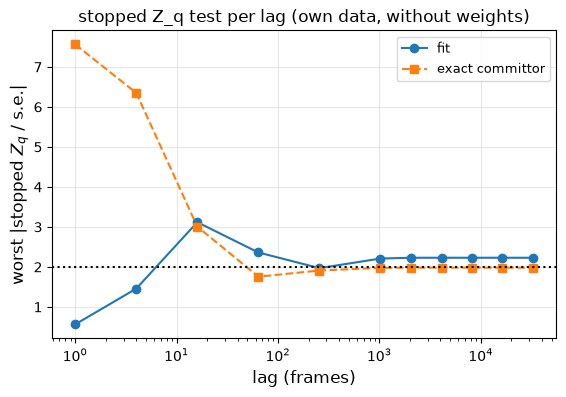

worst |z| per lag (1, 4, 16, 64, 256, 1024, 2048, 4096, 8192, 16284, 32768) : 0.6 1.5 3.1 2.4 2.0 2.2 2.2 2.2 2.2 2.2 2.2


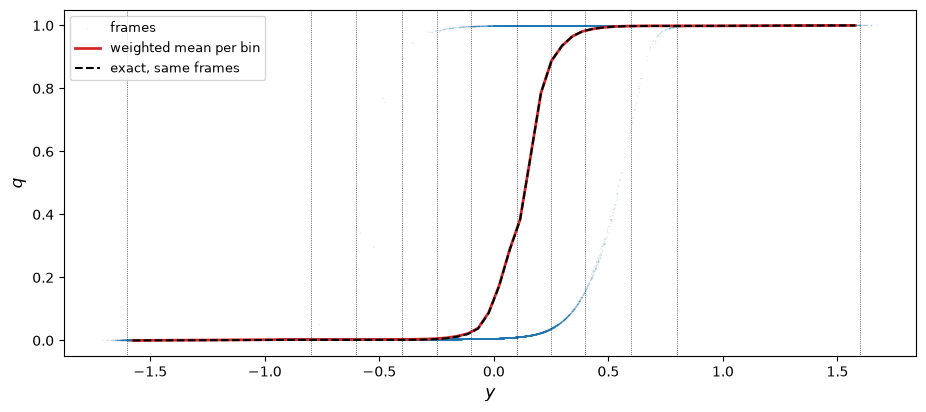

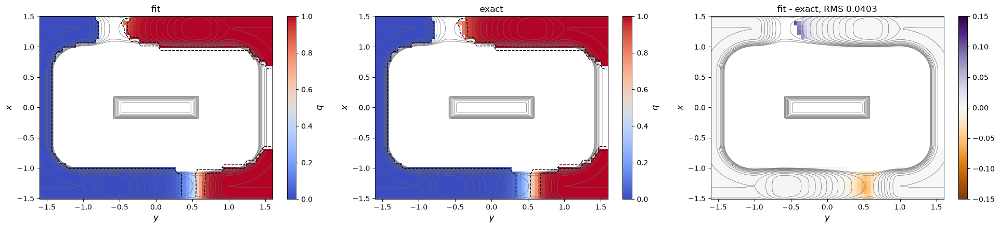

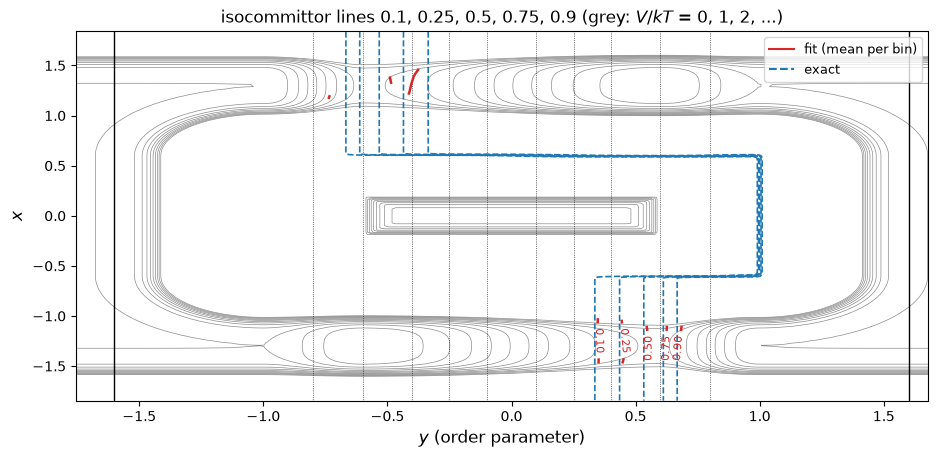

In [14]:
for weighted in FIT_WEIGHTED:
    r, fit_tag, W_fit, results = (fits[weighted][k] for k in ('r', 'tag', 'W', 'results'))
    q_view = types.SimpleNamespace(r_traj=r)
    label = label_of(weighted)
    print(f'===== fit {label}: {fit_tag} =====')
    z_fit = toy2d.z_per_lag(r, b, data.i_traj, W_fit, LAGS, data.group_traj)
    fits[weighted]['z'] = z_fit
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(LAGS, z_fit, 'o-', label='fit')
    if q_exact is not None:
        ax.plot(LAGS, z_exact[weighted], 's--', label='exact committor')
    ax.axhline(2, color='k', ls=':')
    if FIT_LAG > 1:
        ax.axvline(FIT_LAG, color='C3', lw=0.8, label=f'fit lag {FIT_LAG}')
    ax.set(xscale='log', xlabel='lag (frames)', ylabel='worst |stopped $Z_q$ / s.e.|', title=f'stopped Z_q test per lag (own data, {label})')
    ax.legend()
    ax.grid(alpha=0.3)
    save_fig(f'z_per_lag_{fit_tag}')
    plt.show()
    print('worst |z| per lag', LAGS, ':', ' '.join(f'{z:.1f}' for z in z_fit))

    fig, ax = plt.subplots(figsize=(11, 4.5))
    show = np.random.default_rng(0).choice(len(r), size=min(200_000, len(r)), replace=False)
    ax.scatter(Y[show], r[show], s=1, alpha=0.15, edgecolors='none', label='frames')
    bmw = seed_runs.BinnedMean((Y,), (e_y,), free, MIN_COUNT)
    ax.plot(mid_y, bmw(W_fit * r) / bmw(W_fit), 'C3', lw=2, label='weighted mean per bin')
    if prof_ref is not None:
        ax.plot(mid_y, bmw(W_fit * q_exact) / bmw(W_fit), 'k--', lw=1.5, label='exact, same frames')
    for lam in INTFS:
        ax.axvline(lam, color='k', lw=0.5, ls=':')
    ax.set(xlabel='$y$', ylabel='$q$')
    ax.legend()
    save_fig(f'q_vs_order_{fit_tag}')
    plt.show()

    fig = seed_runs.committor_map(planes[:1], mask=free, q_ref=q_exact, min_count=MIN_COUNT)(q_view)
    save_fig(f'result_map_{fit_tag}', fig)
    plt.show()
    if len(planes) > 1:
        fig = seed_runs.committor_map(planes[1:], mask=free, min_count=MIN_COUNT)(q_view)
        save_fig(f'result_velocity_planes_{fit_tag}', fig)
        plt.show()

    p = planes[0]
    bm5 = seed_runs.BinnedMean(p['c'], p['edges'], free, 5)
    (e1, e2) = p['edges']
    m1, m2 = (e1[1:] + e1[:-1]) / 2, (e2[1:] + e2[:-1]) / 2
    levels = [0.1, 0.25, 0.5, 0.75, 0.9]
    fig, ax = plt.subplots(figsize=(11, 4.8))
    draw_potential(ax)
    cs = ax.contour(m1, m2, bm5(r).T, levels=levels, colors='C3', linewidths=1.8)
    ax.clabel(cs, fmt='%.2f', fontsize=8)
    ax.plot([], [], 'C3', label='fit (mean per bin)')
    if ref is not None:
        ax.contour(ref['y'], ref['x'], ref['q'].T, levels=levels, colors='C0', linewidths=1.2, linestyles='--')
        ax.plot([], [], 'C0--', label='exact')
    ax.legend()
    ax.set_title('isocommittor lines 0.1, 0.25, 0.5, 0.75, 0.9 (grey: $V/kT$ = 0, 1, 2, ...)')
    save_fig(f'isocommittor_{fit_tag}')
    plt.show()

    if shoot_idx.size:
        d = r[shoot_idx] - q_shoot
        fig, ax = plt.subplots(figsize=(5.5, 5))
        ax.errorbar(q_shoot, r[shoot_idx], xerr=se_shoot, fmt='.', ms=3, alpha=0.6)
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set(xlabel='shooting', ylabel='fit',
               title=f'fit vs shooting at {len(shoot_idx)} frames: RMS {np.sqrt(np.nanmean(d ** 2)):.3f}\n'
                     f'mean {np.nanmean(d):+.4f} (shooting error {np.nanmean(se_shoot):.3f})')
        save_fig(f'fit_vs_shooting_{fit_tag}')
        plt.show()

    if md_ref is not None:
        # the MD fit, binned on the same (y, x) bins as this fit (mean over the MD frames vs over the path frames)
        bm_md = seed_runs.BinnedMean((md_ref['y'], md_ref['x']), p['edges'], None, MIN_COUNT)
        bm_pf = seed_runs.BinnedMean(p['c'], p['edges'], free, MIN_COUNT)
        Qm, Qp = bm_md(md_ref['q_fit']), bm_pf(r)
        fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
        for ax, (M, title, cmap, lim) in zip(axes, [(Qp, 'staple fit', 'coolwarm', (0, 1)), (Qm, 'MD fit', 'coolwarm', (0, 1)),
                                                   (Qp - Qm, 'staple $-$ MD (bin means)', 'PuOr', (-0.15, 0.15))]):
            im = ax.pcolormesh(e1, e2, M.T, cmap=cmap, vmin=lim[0], vmax=lim[1])
            ax.set(title=title, xlabel='$y$', ylabel='$x$')
            fig.colorbar(im, ax=ax)
        fig.suptitle('Note: for Langevin dynamics the bin means average over different velocity distributions')
        fig.tight_layout()
        save_fig(f'staple_vs_md_{fit_tag}', fig)
        plt.show()

    if len(results) > 1:
        seeds = list(results)
        fig, ax = plt.subplots(figsize=(5.5, 5))
        for s in seeds[1:]:
            ax.plot(results[seeds[0]]['r'][free][::200], results[s]['r'][free][::200], '.', ms=2, label=f'seed {s}')
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set(xlabel=f'seed {seeds[0]}', ylabel='other seeds', title='fits with different seeds (every 200th frame)')
        ax.legend()
        save_fig(f'seeds_{fit_tag}')
        plt.show()
r, fit_tag, results = fits[FIT_WEIGHTED[0]]['r'], fits[FIT_WEIGHTED[0]]['tag'], fits[FIT_WEIGHTED[0]]['results']


## 7b. With and Without Weights

The fits of `FIT_WEIGHTED` side by side, on the same frames:

- the worst stopped z per lag of each fit and of the exact committor, each with the weighting of its fit (the exact committor tests the data: it should pass with the right weights);
- the mean q per bin of the order parameter (weighted by the MC weights in both cases, so the curves compare the fits, not the averaging) with the exact committor;
- on (y, x): each fit − exact, and with weights − without weights;
- a table: RMS against the exact committor per bin (0.05 < q < 0.95), RMS and mean difference against shooting, worst z.


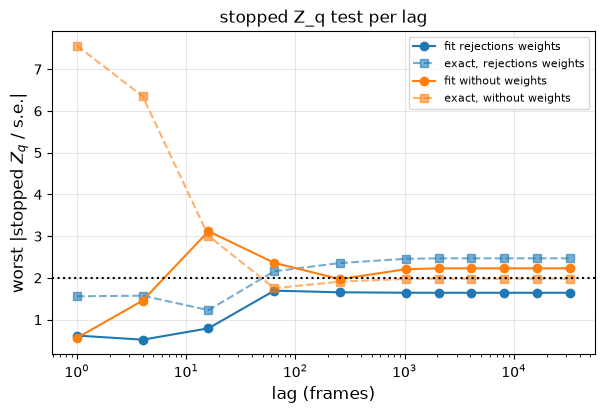

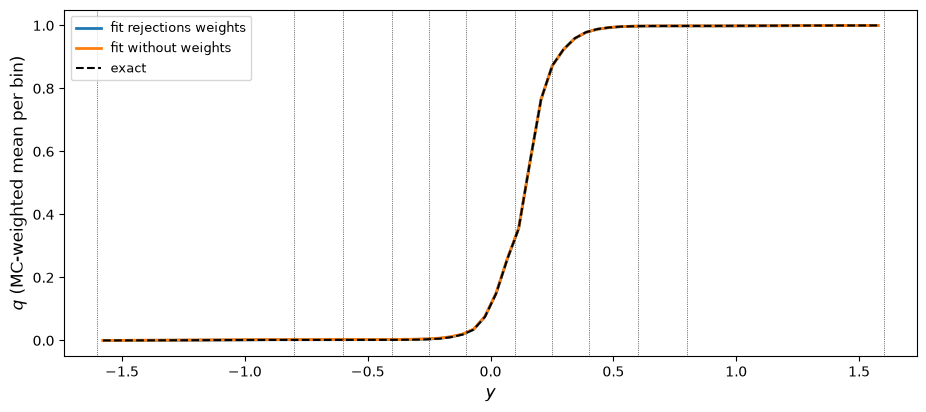

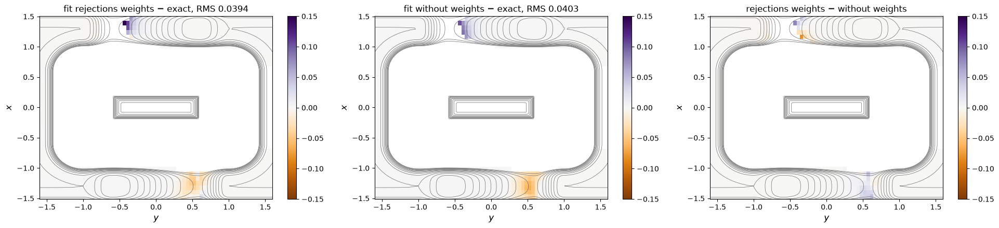

fit                       RMS vs exact  RMS vs shoot  mean - shoot   worst |z| at lags (1, 4, 16, 64, 256, 1024, 2048, 4096, 8192, 16284, 32768)
rejections weights              0.0394           nan          +nan   0.6 0.5 0.8 1.7 1.7 1.6 1.6 1.6 1.6 1.6 1.6
without weights                 0.0403           nan          +nan   0.6 1.5 3.1 2.4 2.0 2.2 2.2 2.2 2.2 2.2 2.2
exact, rejections weights                                             1.6 1.6 1.2 2.2 2.4 2.5 2.5 2.5 2.5 2.5 2.5
exact, without weights                                               7.6 6.4 3.0 1.8 1.9 2.0 2.0 2.0 2.0 2.0 2.0


In [15]:
if len(fits) < 2:
    print('only one fit in FIT_WEIGHTED: nothing to compare')
else:
    names = {w: label_of(w) for w in FIT_WEIGHTED}
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for k, weighted in enumerate(FIT_WEIGHTED):
        ax.plot(LAGS, fits[weighted]['z'], 'o-', color=f'C{k}', label=f'fit {names[weighted]}')
        if q_exact is not None:
            ax.plot(LAGS, z_exact[weighted], 's--', color=f'C{k}', alpha=0.6, label=f'exact, {names[weighted]}')
    ax.axhline(2, color='k', ls=':')
    ax.set(xscale='log', xlabel='lag (frames)', ylabel='worst |stopped $Z_q$ / s.e.|', title='stopped Z_q test per lag')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    save_fig(f'weights_z_per_lag_{tag_for(FIT_WEIGHTED[0])}')
    plt.show()

    bmw = seed_runs.BinnedMean((Y,), (e_y,), free, MIN_COUNT)
    fig, ax = plt.subplots(figsize=(11, 4.5))
    for k, weighted in enumerate(FIT_WEIGHTED):
        ax.plot(mid_y, bmw(W * fits[weighted]['r']) / bmw(W), color=f'C{k}', lw=2, label=f'fit {names[weighted]}')
    if q_exact is not None:
        ax.plot(mid_y, bmw(W * q_exact) / bmw(W), 'k--', lw=1.5, label='exact')
    for lam in INTFS:
        ax.axvline(lam, color='k', lw=0.5, ls=':')
    ax.set(xlabel='$y$', ylabel='$q$ (MC-weighted mean per bin)')
    ax.legend()
    save_fig(f'weights_q_vs_order_{tag_for(FIT_WEIGHTED[0])}')
    plt.show()

    p = planes[0]
    bm = seed_runs.BinnedMean(p['c'], p['edges'], free, MIN_COUNT)
    (e1, e2) = p['edges']
    Q = {w: bm(fits[w]['r']) for w in FIT_WEIGHTED}
    panels = []
    if q_exact is not None:
        Qe = bm(q_exact)
        trans = (Qe > 0.05) & (Qe < 0.95)
        panels += [(Q[w] - Qe, f'fit {names[w]} $-$ exact, RMS {np.sqrt(np.nanmean((Q[w] - Qe)[trans] ** 2)):.4f}') for w in FIT_WEIGHTED]
    panels.append((Q[FIT_WEIGHTED[0]] - Q[FIT_WEIGHTED[1]], f'{names[FIT_WEIGHTED[0]]} $-$ {names[FIT_WEIGHTED[1]]}'))
    fig, axes = plt.subplots(1, len(panels), figsize=(6.5 * len(panels), 4.5), squeeze=False)
    for ax, (M, title) in zip(axes[0], panels):
        im = ax.pcolormesh(e1, e2, M.T, cmap='PuOr', vmin=-0.15, vmax=0.15)
        g1, g2, Vc, lev = CONTOURS
        ax.contour(g1, g2, Vc.T, levels=lev, colors='0.4', linewidths=0.5)
        ax.set(title=title, xlabel='$y$', ylabel='$x$', xlim=(e1[0], e1[-1]), ylim=(e2[0], e2[-1]))
        fig.colorbar(im, ax=ax)
    fig.tight_layout()
    save_fig(f'weights_maps_{tag_for(FIT_WEIGHTED[0])}', fig)
    plt.show()

    print(f'{"fit":24s} {"RMS vs exact":>13s} {"RMS vs shoot":>13s} {"mean - shoot":>13s}   worst |z| at lags {LAGS}')
    for w in FIT_WEIGHTED:
        rr = fits[w]['r']
        rms_ex = np.sqrt(np.nanmean((Q[w] - Qe)[trans] ** 2)) if q_exact is not None else np.nan
        rms_sh = np.sqrt(np.nanmean((rr[shoot_idx] - q_shoot) ** 2)) if shoot_idx.size else np.nan
        mean_sh = np.nanmean(rr[shoot_idx] - q_shoot) if shoot_idx.size else np.nan
        print(f'{names[w]:24s} {rms_ex:13.4f} {rms_sh:13.4f} {mean_sh:+13.4f}   ' + ' '.join(f'{z:.1f}' for z in fits[w]['z']))
    if q_exact is not None:
        for w in FIT_WEIGHTED:
            print(f'{"exact, " + names[w]:24s} {"":13s} {"":13s} {"":13s}   ' + ' '.join(f'{z:.1f}' for z in z_exact[w]))


## 8. Save

The fitted q per frame with the frames, pieces, weights and references, as `FIG_DIR/committor_<fit tag>.npz`, one file per fit of `FIT_WEIGHTED` (`path_weights`: the weights the fit used; `weights_used`: their scheme).

In [16]:
for weighted in FIT_WEIGHTED:
    fit = fits[weighted]
    W_fit_saved = fit['W']
    out = f'{FIG_DIR}/committor_{fit["tag"]}.npz'
    np.savez(out, q_fit=fit['r'].astype(np.float32), X_all=data.X_all.astype(np.float32), i_traj=data.i_traj,
             group_traj=data.group_traj, t_traj=data.t_traj, path_weights=W_fit_saved, weights_used=scheme_of(weighted), boundary0=A, boundary1=B,
             q_exact=(q_exact if q_exact is not None else np.full(len(fit['r']), np.nan)).astype(np.float32),
             shoot_idx=shoot_idx, q_shoot=q_shoot if shoot_idx.size else [], z_fit=fit['z'], lags=LAGS,
             settings=repr(dict(run=RUN, cvs=CVS, fit_lag=FIT_LAG, reversed=REVERSED, weights=scheme_of(weighted),
                                stopped_ends=STOPPED_ENDS, paths_per_ensemble=PATHS_PER_ENSEMBLE, path_seed=PATH_SEED,
                                max_length=MAX_LENGTH, envelope=ENVELOPE, fit_gamma=FIT_GAMMA, ny=NY, max_iter=MAX_ITER,
                                warmup=WARMUP_ITER, seeds=FIT_SEEDS)))
    print('saved', out)


saved /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/committor_rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped.npz
saved /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/committor_rev_none_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped.npz


## 9. Fit on New Fixed-Length Trajectories from Random Path Frames

A second, independent data set (the PI's validation): `FT_N_POINTS` random frames of the path data (uniform over the frames outside A and B, or with `FT_START = 'q_bins'` equal numbers in 10 bins of the path-data fit: the path frames crowd near the interfaces and, on the 2D Z, on the plateau), one new trajectory of the run's dynamics from each (`toy2d.Integrator`), `FT_LENGTH` steps long or shorter if it reaches A or B (absorption checked every step, as in the run). Compared with the first fit of `FIT_WEIGHTED`. NPNEq is fitted on these trajectories with the same CVs, fit lag and fit settings as the path data, without weights.

- The new trajectories are plain dynamics: no path selection, no cut at M, no mirrored pieces, no MC weights. A fit on them is unbiased whatever the start distribution, so it tests what the path-data preparation and weights may have introduced.
- Langevin trajectories start with the frame's recorded velocity (needed, as for shooting). `dy`/`dx` CVs are the change over the last step / dt (at the start frame: the data's value).
- Compared at the start frames (each is a frame of both data sets): the new fit against the path-data fit, and both against the exact committor (Brownian runs). Also the stopped Z_q test per lag on the new data, and the maps.
- **Limits:** like the path data, trajectories of length L fix the level of q only through the ones that reach A or B (printed as the absorbed fraction). A region the trajectories do not leave within L (a plateau) has its level set only by the smoothness of the fit, as for the staple pieces. Make L longer to test levels.
- Cost: `FT_N_POINTS` × L frames (10k × the median piece length is a few million frames, a fraction of the path data).

['q_fit', 'X_all', 'i_traj', 'group_traj', 't_traj', 'path_weights', 'weights_used', 'boundary0', 'boundary1', 'q_exact', 'shoot_idx', 'q_shoot', 'z_fit', 'lags', 'settings']
14041 trajectories of up to 500 steps in 889 s; 26% reached A or B
6,250,793 frames; 202 in A, 3391 in B
#=500, dr2=160.032, zqs_z=2.1888, sdzqs=3.42946, |dx|=0.439671, time=18.1501
#=1000, dr2=160.032, zqs_z=2.18891, sdzqs=3.42952, |dx|=1.78565e-06, time=31.2283
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped_newtraj_n14041_L500/seed0/it1000 ---


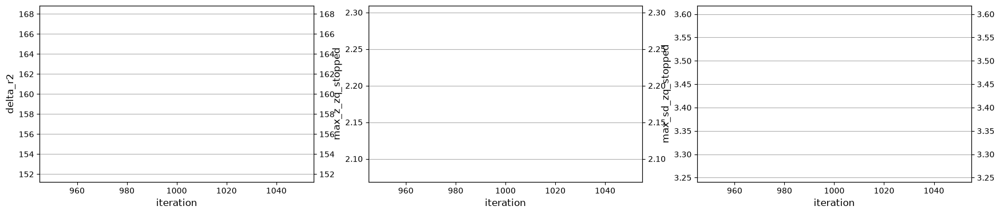

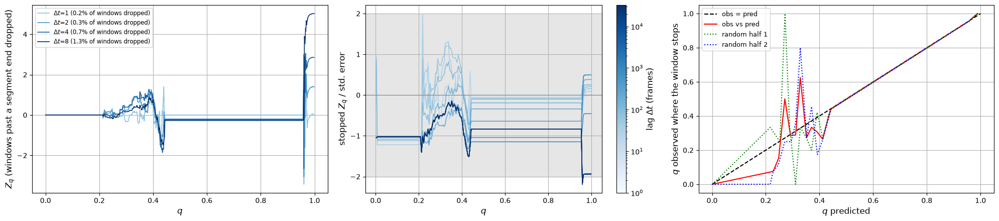

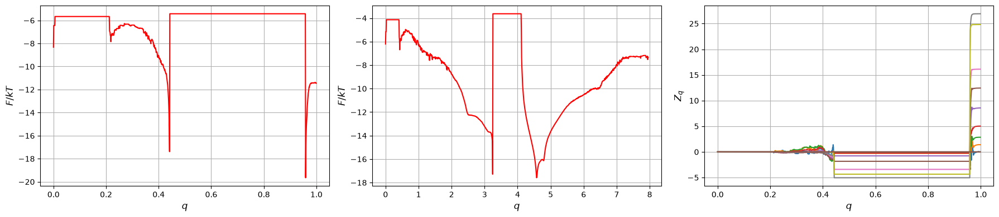

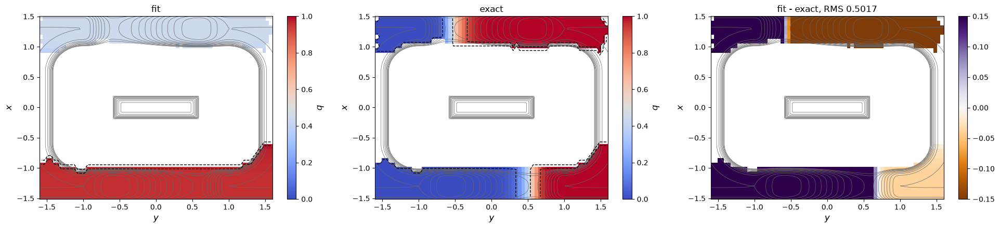

new-trajectory fit: 1000 iterations (warm-up, envelope 1000000)
#=1500, dr2=160.033, zqs_z=2.18865, sdzqs=3.40992, |dx|=0.000169625, time=9.83608
#=2000, dr2=228.892, zqs_z=11.8829, sdzqs=47.0003, |dx|=0.167037, time=19.5162
#=2500, dr2=2200.1, zqs_z=1.80554, sdzqs=14.4417, |dx|=0.641496, time=29.3116
#=3000, dr2=2202.03, zqs_z=1.78135, sdzqs=14.4394, |dx|=0.000523678, time=42.2187
#=3500, dr2=2183.08, zqs_z=1.87576, sdzqs=14.3718, |dx|=0.00378966, time=59.4611
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped_newtraj_n14041_L500/seed0/it3500 ---


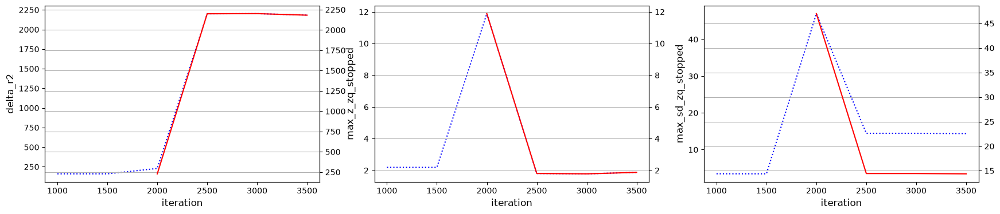

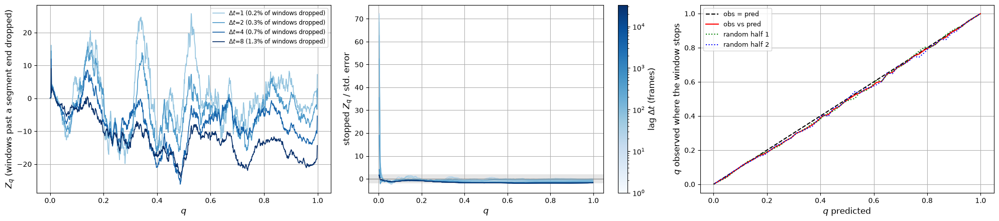

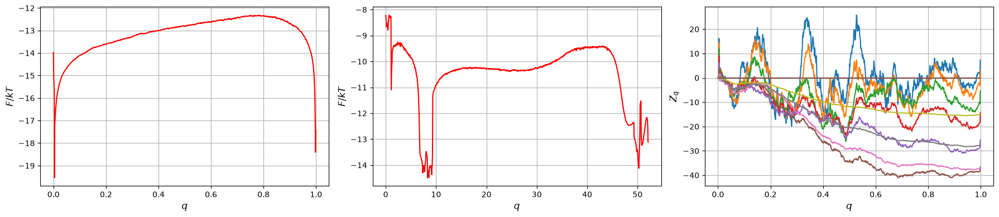

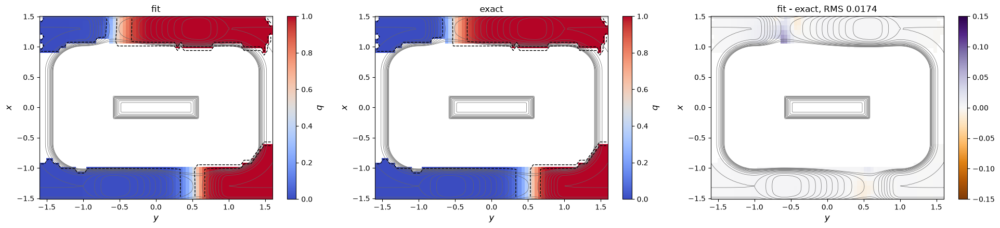

new-trajectory fit: 3500 iterations (main, envelope 0.01)
#=4000, dr2=2205.57, zqs_z=1.57533, sdzqs=12.356, |dx|=0.00261077, time=10.0778
#=4500, dr2=2202.76, zqs_z=1.70569, sdzqs=13.6283, |dx|=0.000243261, time=19.87
#=5000, dr2=2203.09, zqs_z=1.71198, sdzqs=13.6281, |dx|=0.000190462, time=29.6353
#=5500, dr2=2185.46, zqs_z=2.63133, sdzqs=20.832, |dx|=0.0014283, time=39.5376
#=6000, dr2=2201.52, zqs_z=1.69871, sdzqs=12.9789, |dx|=0.00133259, time=52.1968
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped_newtraj_n14041_L500/seed0/it6000 ---


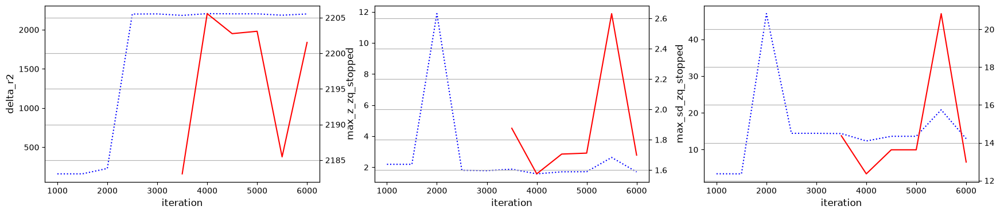

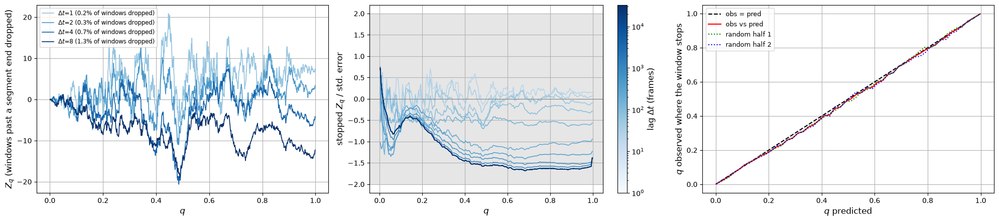

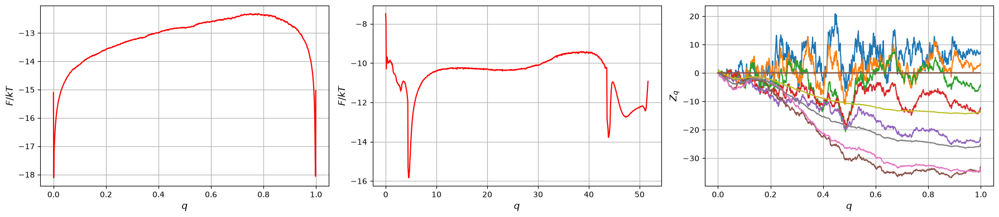

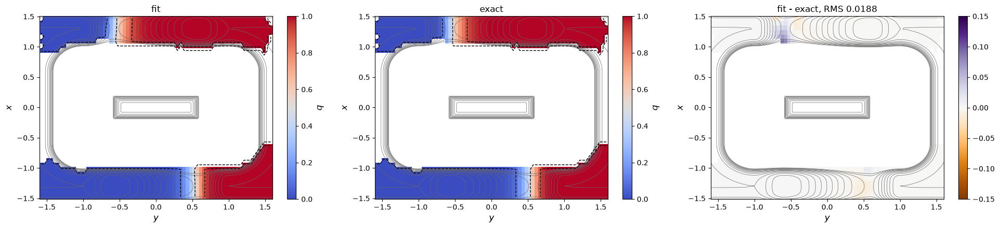

new-trajectory fit: 6000 iterations (main, envelope 0.01)
#=6500, dr2=2202.78, zqs_z=1.70128, sdzqs=13.5146, |dx|=0.000457067, time=15.1446
#=7000, dr2=2201.61, zqs_z=1.77862, sdzqs=14.1142, |dx|=0.000234936, time=25.3545
#=7500, dr2=2202.01, zqs_z=1.78696, sdzqs=14.3307, |dx|=0.00016906, time=35.1835
#=8000, dr2=2201.92, zqs_z=1.78595, sdzqs=14.3191, |dx|=6.51058e-05, time=44.9775
#=8500, dr2=2201.89, zqs_z=1.78783, sdzqs=14.3292, |dx|=4.30157e-05, time=54.7726
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped_newtraj_n14041_L500/seed0/it8500 ---


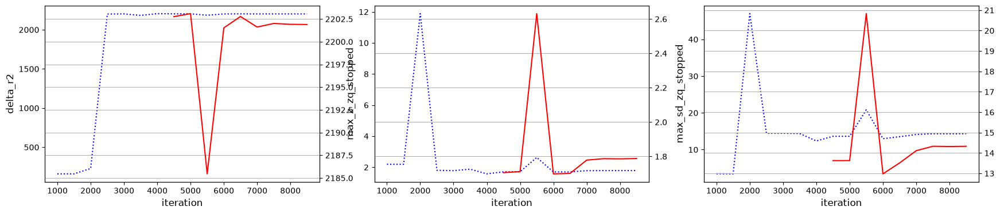

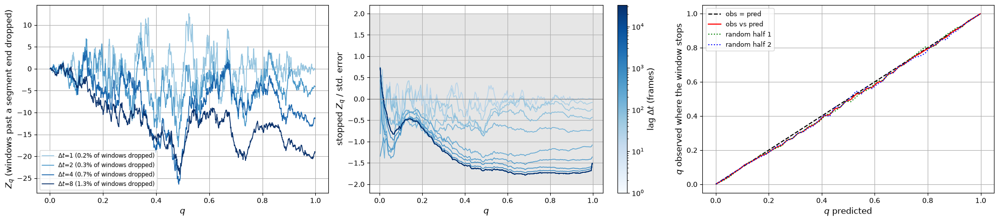

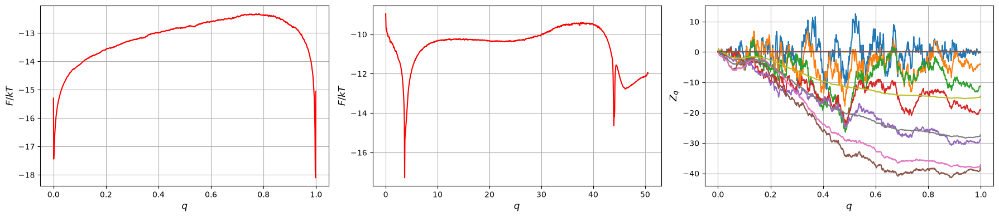

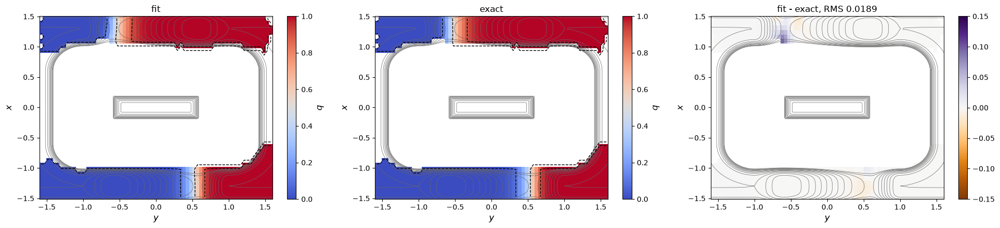

new-trajectory fit: 8500 iterations (main, envelope 0.01)
#=9000, dr2=2202.48, zqs_z=1.79327, sdzqs=14.3288, |dx|=0.000164165, time=14.8997
#=9500, dr2=2086.17, zqs_z=8.68171, sdzqs=36.6165, |dx|=0.0218799, time=32.3308
#=10000, dr2=2200.11, zqs_z=1.80406, sdzqs=14.381, |dx|=0.0214389, time=43.4734
#=10500, dr2=2201.95, zqs_z=1.76698, sdzqs=14.141, |dx|=0.000364934, time=53.1908
#=11000, dr2=2202.46, zqs_z=1.76018, sdzqs=14.067, |dx|=0.000177418, time=62.999
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped_newtraj_n14041_L500/seed0/it11000 ---


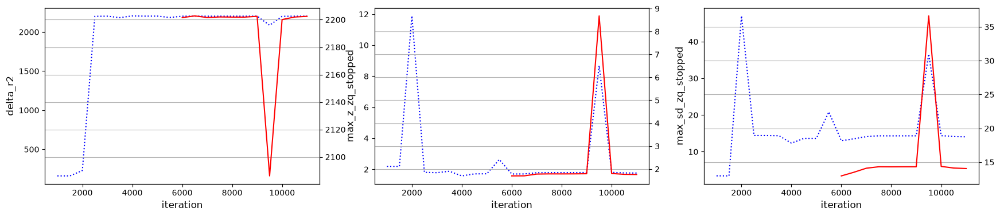

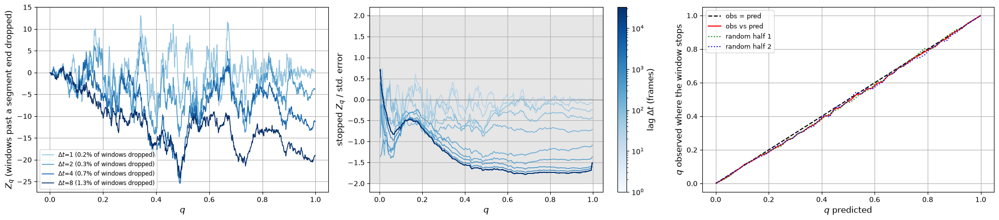

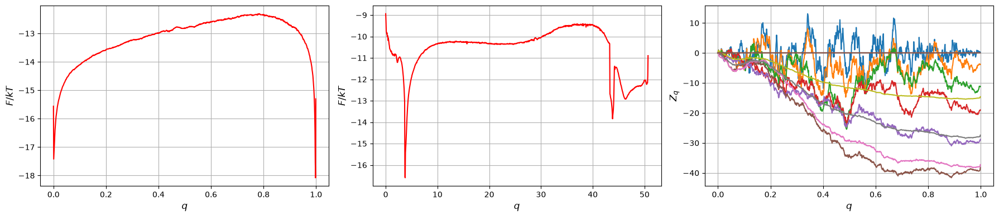

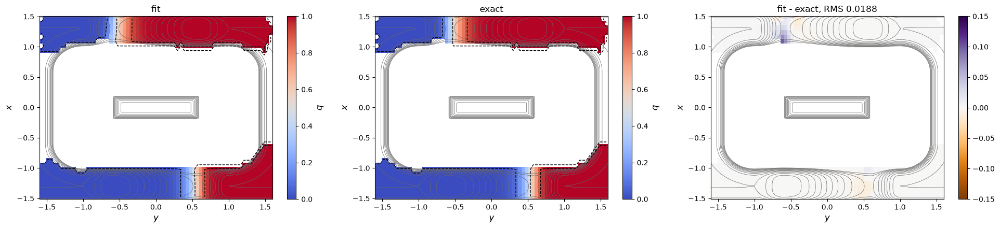

new-trajectory fit: 11000 iterations (main, envelope 0.01)
#=11500, dr2=2201.89, zqs_z=1.78393, sdzqs=14.3309, |dx|=0.000149225, time=9.65268
#=12000, dr2=2202.82, zqs_z=1.78576, sdzqs=14.4096, |dx|=0.000491106, time=22.7967
#=12500, dr2=2204.72, zqs_z=1.76356, sdzqs=14.3294, |dx|=0.000548647, time=39.9387
#=13000, dr2=2203.24, zqs_z=1.79221, sdzqs=14.5185, |dx|=0.000444839, time=53.0022
#=13500, dr2=2201.26, zqs_z=1.78879, sdzqs=14.3448, |dx|=0.000541042, time=63.0598
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped_newtraj_n14041_L500/seed0/it13500 ---


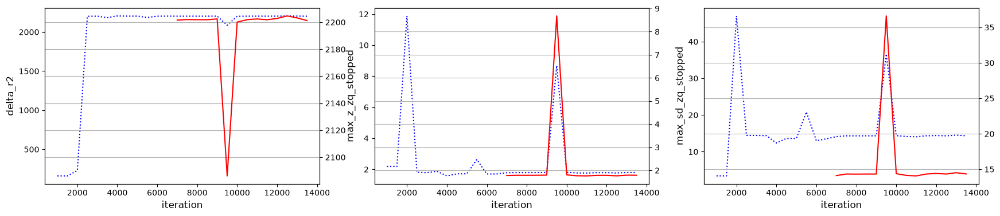

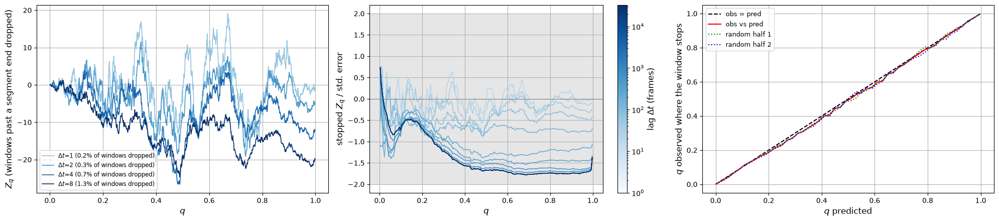

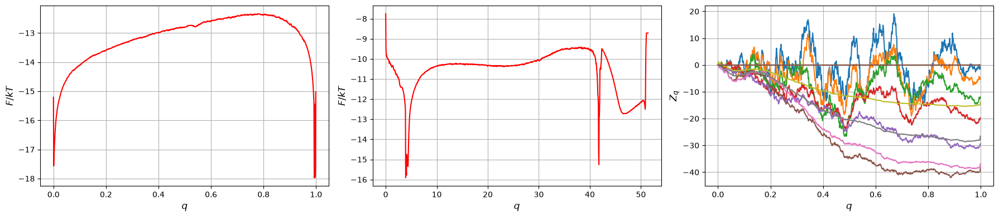

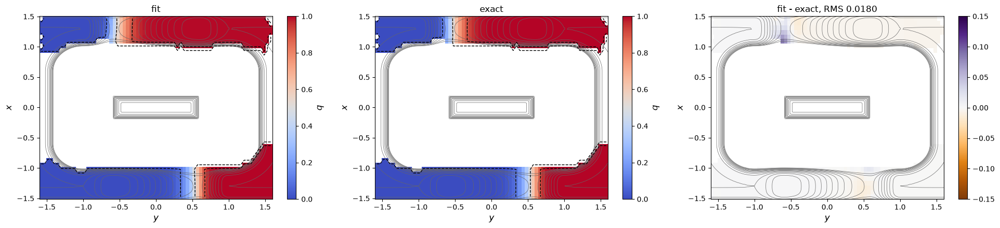

new-trajectory fit: 13500 iterations (main, envelope 0.01)
#=14000, dr2=2201.9, zqs_z=1.78982, sdzqs=14.4013, |dx|=0.00140045, time=9.62667
#=14500, dr2=2202.27, zqs_z=1.78769, sdzqs=14.294, |dx|=0.000369533, time=19.2108
#=15000, dr2=2200.89, zqs_z=1.80366, sdzqs=14.3415, |dx|=0.000300829, time=30.4654
#=15500, dr2=2202.13, zqs_z=1.79099, sdzqs=14.3658, |dx|=0.000695867, time=47.8361
#=16000, dr2=2202.25, zqs_z=1.79715, sdzqs=14.4471, |dx|=0.000375174, time=62.5935
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped_newtraj_n14041_L500/seed0/it16000 ---


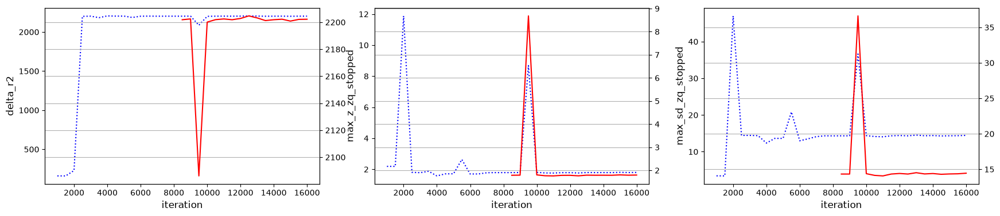

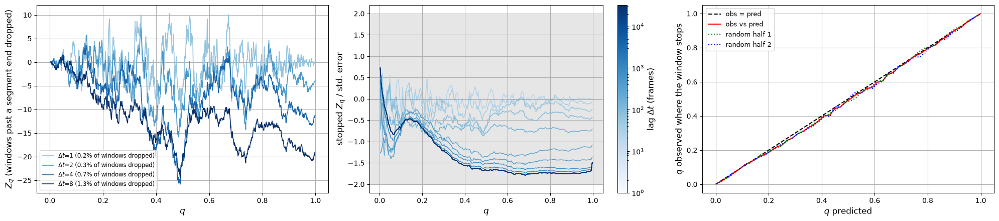

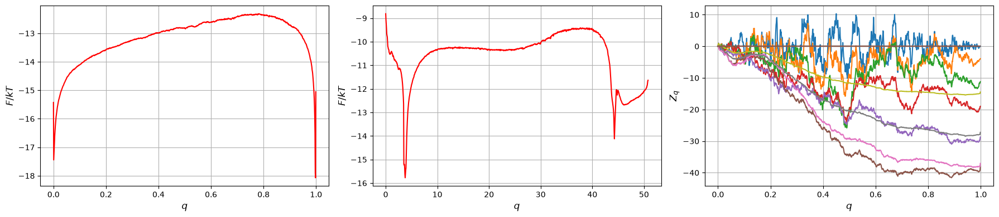

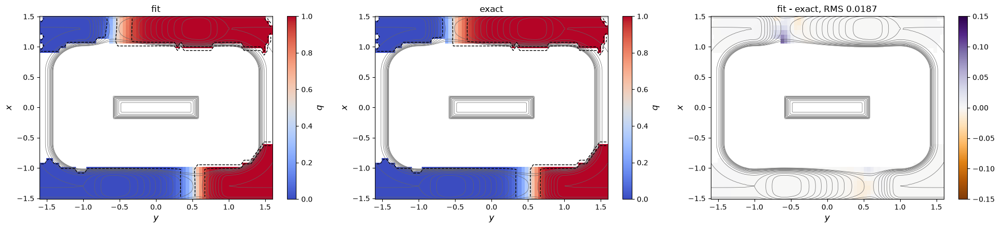

new-trajectory fit: 16000 iterations (main, envelope 0.01)
new data, new fit: worst |stopped z| at lags (1, 4, 16, 64, 256, 1024, 2048, 4096, 8192, 16284, 32768) : 0.6 0.8 0.9 1.5 1.7 1.8 1.8 1.8 1.8 1.8 1.8
at the 14041 start frames: new-trajectory fit - path-data fit: mean +0.0107, RMS 0.0309
at the 14041 start frames: new-trajectory fit - exact: mean -0.0060, RMS 0.0078
at the 14041 start frames: path-data fit - exact: mean -0.0167, RMS 0.0347


NameError: name 'z_fit' is not defined

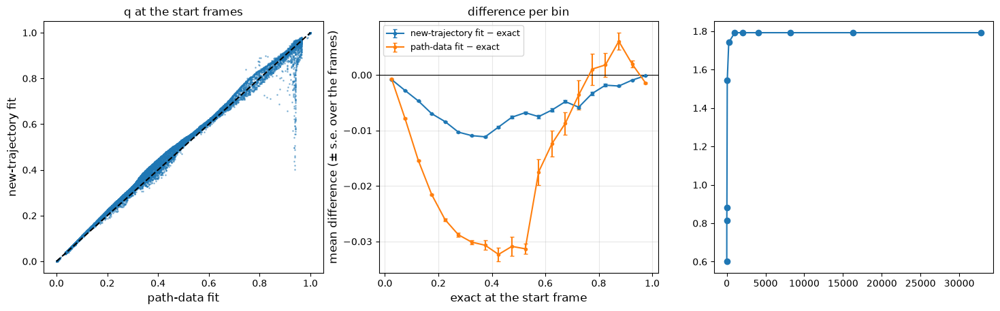

In [12]:
# New data: fixed-length trajectories from random path frames, and an NPNEq fit on them
import types
FT_N_POINTS = 20_000      # random start frames (uniform over the free frames of the path data)
FT_LENGTH = 500          # steps per trajectory; None: the median piece length
FT_START = 'q_bins'      # 'uniform': random free frames; 'q_bins': equal numbers in 10 bins of the path-data fit
FT_SEED = 0
FT_MAX_ITER, FT_CHUNK = 15000, CHUNK          # fit settings; the rest as for the path data

#if not (hasattr(pot, 'potential_and_force_xy') and (BROWNIAN or V_ORD)):
#    raise RuntimeError('new trajectories need a vectorized potential, and recorded velocities for Langevin runs '
#                       '(everything above, including the saved fits, is complete)')
q = np.load('/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures_by_potential/2d_staggered_channels/brownian_g1/staple_stagd3g1bdalt_istar_s0/committor_rev_rejections_p6000_s0_y-x_lag1_env0.01_g0_it10000_stopped.npz')
#r_path = cp.asnumpy(q.r_traj)                    # the path-data fit (q is reused below)
print(list(q.keys()))
r_path = q['q_fit']

# 1. start frames and trajectories (all at once on the GPU; a trajectory stops when it reaches A or B)
rng = np.random.default_rng(FT_SEED)
if FT_START == 'uniform':
    start = np.sort(rng.choice(np.flatnonzero(free), size=FT_N_POINTS, replace=False))
else:                                            # the path frames crowd near the interfaces and on plateaus
    q_bin = np.clip((r_path * 30).astype(int), 0, 29)
    start = np.sort(np.concatenate([rng.choice(np.flatnonzero(free & (q_bin == k)), replace=False,
                                               size=min(FT_N_POINTS // 30, np.sum(free & (q_bin == k))))
                                    for k in range(30)]))
FT_N_POINTS = len(start)
L = FT_LENGTH or int(np.median(lengths))
engine = toy2d.Integrator(pot, DT, KT, GAMMA, MASS, BROWNIAN, xp=cp, seed=FT_SEED)
y, x = cp.asarray(Y[start]), cp.asarray(X[start])
vy = cp.asarray(cols['vy'][start]) if V_ORD else cp.zeros(FT_N_POINTS)
vx = cp.asarray(cols['vx'][start]) if V_ORD else cp.zeros(FT_N_POINTS)
frames = {c: cp.zeros((L + 1, FT_N_POINTS)) for c in ('y', 'x', 'vy', 'vx')}    # frames[c][step, trajectory]
for c, v in zip(('y', 'x', 'vy', 'vx'), (y, x, vy, vx)):
    frames[c][0] = v
last = cp.full(FT_N_POINTS, L)                   # last frame of each trajectory
running = cp.ones(FT_N_POINTS, bool)
t0 = time.time()
for step in range(1, L + 1):
    y, x, vy, vx = engine.step(y, x, vy, vx)
    for c, v in zip(('y', 'x', 'vy', 'vx'), (y, x, vy, vx)):
        frames[c][step] = v
    hit = running & ((y <= LAMBDA_A) | (y >= LAMBDA_B))
    last = cp.where(hit, step, last)
    running &= ~hit
print(f'{FT_N_POINTS} trajectories of up to {L} steps in {time.time() - t0:.0f} s; '
      f'{float(1 - running.mean()):.0%} reached A or B')

# 2. flatten to the fit's format: one segment per trajectory, frames 0 .. last
last = cp.asnumpy(last)
keep = (np.arange(L + 1)[:, None] <= last[None, :]).T                 # [trajectory, step]
ft = {c: cp.asnumpy(v).T[keep] for c, v in frames.items()}
del frames
ft_i = np.repeat(np.arange(FT_N_POINTS), last + 1)
ft_t = np.concatenate([np.arange(n + 1) for n in last]).astype(float)
ft_first = np.r_[0, np.cumsum(last + 1)[:-1]]                         # index of each start frame
ft_A, ft_B = ft['y'] <= LAMBDA_A, ft['y'] >= LAMBDA_B
ft_b = ft_A | ft_B
ft_free = ~ft_b
step_back = np.where(ft_t > 0, np.arange(len(ft_t)) - 1, np.arange(len(ft_t)))
ft_cols = {'y': ft['y'], 'x': ft['x'], 'vy': ft['vy'], 'vx': ft['vx'],
           'dy': (ft['y'] - ft['y'][step_back]) / DT, 'dx': (ft['x'] - ft['x'][step_back]) / DT}
for c in ('dy', 'dx'):                           # the start frame keeps the data's finite difference
    if c in cols:
        ft_cols[c][ft_first] = cols[c][start]
ft_q_exact = None
if ref is not None:
    ft_q_exact = toy2d.interp_grid(ref, ft['y'], ft['x'])
    ft_q_exact[ft_A], ft_q_exact[ft_B] = 0.0, 1.0
print(f'{len(ft_t):,} frames; {ft_A.sum()} in A, {ft_B.sum()} in B')

# 3. NPNEq fit on the new trajectories: same CVs, lag and settings, no weights
ft_X_cv = cp.asarray(np.column_stack([ft_cols[c] for c in CVS]))
ft_fit_kw = dict(ny=NY, print_step=PRINT_STEP, save_min_metric='max_z_zq_stopped',
                 metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'),
                 **toy2d.lag_update(optimalrcs, ft_i, ft_b, None, FIT_LAG))
ft_plane = seed_runs.plane(ft['y'], e_y, '$y$', ft['x'], e_x, '$x$', CONTOURS)
ft_extras = {'q_map': seed_runs.committor_map([ft_plane], mask=ft_free, q_ref=ft_q_exact, min_count=MIN_COUNT)}
ft_folder = f'{FIG_DIR}/{fit_tag}_newtraj_n{FT_N_POINTS}_L{L}/seed{FT_SEED}'
np.random.seed(FT_SEED)
cp.random.seed(FT_SEED)
ft_comp_y = lambda: ft_X_cv[:, np.random.randint(ft_X_cv.shape[1])]

q_ft = optimalrcs.CommittorNE(boundary0=ft_A, boundary1=ft_B, i_traj=ft_i, t_traj=ft_t)   # one segment per trajectory
q_ft.set_fixed_traj_length_trap(ft_b, FT_LENGTH)   # trajectories end in A/B or after L steps (a fixed length)
n_done = 0
for n_iter, env, stage in [(WARMUP_ITER, WARMUP_ENVELOPE, 'warm-up')] + [(FT_CHUNK, ENVELOPE, 'main')] * (FT_MAX_ITER // FT_CHUNK):
    if n_iter == 0:
        continue
    optimalrcs.envelope_scale = env
    q_ft.fit_transform(ft_comp_y, gamma=FIT_GAMMA, max_iter=n_iter, **ft_fit_kw)
    n_done += n_iter
    seed_runs.save_and_show(q_ft, ft_folder, f'it{n_done}', ('metrics', 'tis', 'feps'), dict(metrics=METRICS), ft_extras)
    print(f'new-trajectory fit: {n_done} iterations ({stage}, envelope {env})', flush=True)
r_ft = cp.asnumpy(q_ft.r_traj)
del ft_X_cv, q_ft
cp.get_default_memory_pool().free_all_blocks()
toy2d.lag_update(optimalrcs, data.i_traj, b, W, FIT_LAG)              # the path data's update back in place

# 4. comparison at the start frames, and the stopped Z_q test on the new data
z_ft = toy2d.z_per_lag(r_ft, ft_b, ft_i, None, LAGS)
print('new data, new fit: worst |stopped z| at lags', LAGS, ':', ' '.join(f'{z:.1f}' for z in z_ft))
at_start = {'new-trajectory fit': r_ft[ft_first], 'path-data fit': r_path[start]}
if q_exact is not None:
    at_start['exact'] = q_exact[start]
names = list(at_start)
for i, a in enumerate(names):
    for c in names[i + 1:]:
        d = at_start[a] - at_start[c]
        print(f'at the {FT_N_POINTS} start frames: {a} - {c}: mean {d.mean():+.4f}, RMS {np.sqrt(np.mean(d ** 2)):.4f}')
q_bins = np.linspace(0, 1, 21)
q_mid = (q_bins[1:] + q_bins[:-1]) / 2
ref_name = 'exact' if q_exact is not None else 'path-data fit'
k = np.clip(np.digitize(at_start[ref_name], q_bins) - 1, 0, len(q_mid) - 1)
cnt = np.bincount(k, minlength=len(q_mid))
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8))
ax1.plot(at_start['path-data fit'], at_start['new-trajectory fit'], '.', ms=2, alpha=0.4)
ax1.plot([0, 1], [0, 1], 'k--')
ax1.set(xlabel='path-data fit', ylabel='new-trajectory fit', title='q at the start frames')
for name in names:
    if name == ref_name:
        continue
    d = at_start[name] - at_start[ref_name]
    mean = np.bincount(k, weights=d, minlength=len(q_mid)) / np.maximum(cnt, 1)
    sd = np.sqrt(np.maximum(np.bincount(k, weights=d ** 2, minlength=len(q_mid)) / np.maximum(cnt, 1) - mean ** 2, 0))
    ok = cnt >= 10
    ax2.errorbar(q_mid[ok], mean[ok], yerr=sd[ok] / np.sqrt(cnt[ok]), fmt='o-', ms=3, capsize=2,
                 label=f'{name} $-$ {ref_name}')
ax2.axhline(0, color='k', lw=0.8)
ax2.set(xlabel=f'{ref_name} at the start frame', ylabel='mean difference (± s.e. over the frames)', title='difference per bin')
ax2.legend()
ax2.grid(alpha=0.3)
ax3.plot(LAGS, z_ft, 'o-', label='new-trajectory fit, new data')
ax3.plot(LAGS, z_fit, 's--', label='path-data fit, path data')
ax3.axhline(2, color='k', ls=':')
ax3.set(xscale='log', xlabel='lag (frames)', ylabel='worst |stopped $Z_q$ / s.e.|', title='stopped Z_q test, each on its own data')
ax3.legend()
ax3.grid(alpha=0.3)
fig.suptitle(f'{FT_N_POINTS} new trajectories of up to {L} steps from random path frames')
fig.tight_layout()
save_fig(f'newtraj_comparison_{fit_tag}_n{FT_N_POINTS}_L{L}', fig)
plt.show()
fig = seed_runs.committor_map([ft_plane], mask=ft_free, q_ref=ft_q_exact, min_count=MIN_COUNT)(
    types.SimpleNamespace(r_traj=cp.asarray(r_ft)))
save_fig(f'newtraj_map_{fit_tag}_n{FT_N_POINTS}_L{L}', fig)
plt.show()